# Partie I : Exploration, preprocessing, non supervisé

**Objectif de ce notebook** : charger le dataset *Myocardial infarction complications* et produire trois objets, utilisés ensuite par tout le groupe :

| Objet | Contenu |
|---|---|
| `y` | la cible : le patient est-il décédé (1) ou a-t-il survécu (0) ? |
| `X_admission` | les variables connues **à l'admission** à l'hôpital |
| `X_jour3` | les variables connues **au 3ᵉ jour** (toutes les variables d'entrée) |

**Pourquoi deux jeux de variables ?** On veut savoir si l'on peut prédire les complications dès l'arrivée du patient, puis si les informations recueillies pendant 3 jours améliorent la prédiction. Utiliser au jour 0 une information qui n'existe qu'au jour 3 serait de la **fuite de données** (*data leakage*) : le modèle paraîtrait excellent mais serait inutilisable en pratique.

Le dataset contient 1700 patients, 111 variables d'entrée (*features*) et 12 complications possibles.

## I - Chargement des données

### I.1 - Import des bibliothèques

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

### I.2 - Chargement du fichier CSV

Le fichier doit se trouver à côté du notebook ou dans un dossier `data/`. La cellule ci-dessous cherche à plusieurs endroits et affiche un message clair si elle ne trouve rien (c'était la cause du `FileNotFoundError`).

On utilise `index_col="ID"` : la colonne `ID` identifie le patient, ce n'est pas une variable à donner au modèle.

In [4]:
NAME_FILES = "Myocardial_infarction_complications_Database.csv"
PATH_FILES = [NAME_FILES, os.path.join("data", NAME_FILES), os.path.join("..", "data", NAME_FILES)]

chemin = next((c for c in PATH_FILES if os.path.exists(c)), None)
if chemin is None:
    raise FileNotFoundError(
        f"{NAME_FILES} introuvable. Cherché dans : {PATH_FILES}. "
        "Copiez le CSV dans le dossier du notebook ou dans data/."
    )

df = pd.read_csv(chemin, index_col="ID")
print("Fichier chargé :", chemin)
print("Dimensions :", df.shape)   # attendu : (1700, 123) = 111 entrées + 12 complications

Fichier chargé : Myocardial_infarction_complications_Database.csv
Dimensions : (1700, 123)


> ⚠️ **Attention** : Les valeurs manquantes sont des **cases vides** dans le CSV, que pandas lit directement comme `NaN` (pas besoin de `na_values="?"`).



## II - Exploration des donnnées

### II.1 - Séparation des variables d'entrée et de complications

Les 12 dernières colonnes sont des **complications** (ce qu'on veut prédire). Toutes les autres sont des variables d'entrée.

On les sélectionne **par leur nom** et non par leur position (`iloc[:, 2:113]`). Avec un numéro, un décalage d'une colonne passe inaperçu et peut mettre une complication dans `X`, ce qui donne une fuite de données.

In [5]:
COMPLICATIONS = [
    "FIBR_PREDS",  # fibrillation auriculaire
    "PREDS_TAH",   # tachycardie supraventriculaire
    "JELUD_TAH",   # tachycardie ventriculaire
    "FIBR_JELUD",  # fibrillation ventriculaire
    "A_V_BLOK",    # bloc auriculo-ventriculaire du 3e degré
    "OTEK_LANC",   # œdème pulmonaire
    "RAZRIV",      # rupture myocardique
    "DRESSLER",    # syndrome de Dressler
    "ZSN",         # insuffisance cardiaque chronique
    "REC_IM",      # récidive d'infarctus
    "P_IM_STEN",   # angine post-infarctus
    "LET_IS",      # issue létale : 0 = survie, 1 à 7 = cause du décès
]

X_all = df.drop(columns=COMPLICATIONS)


### II.2 - Définion La cible `y` : `LET_IS` décès ou survie

`LET_IS` vaut 0 si le patient survit, et de 1 à 7 selon la cause du décès (1 choc cardiogénique, 2 œdème pulmonaire, 3 rupture myocardique, 4 aggravation de l'insuffisance cardiaque, 5 thromboembolie, 6 asystolie, 7 fibrillation ventriculaire).

On la **binarise** : 0 = survie, 1 = décès (quelle qu'en soit la cause). On obtient un problème de classification binaire.

Répartition de la variable LET_IS
LET_IS
survie    1429
décès      271
Name: count, dtype: int64
Proportion de décès : 15.9%


/tmp/ipykernel_2286/4077846963.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  y.iloc[i] = 1
/tmp/ipykernel_2286/4077846963.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  y.iloc[i] = 1
/tmp/ipykernel_2286/4077846963.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  y.iloc[i] = 1
/tmp/ipykernel_2286/4077846963.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in 

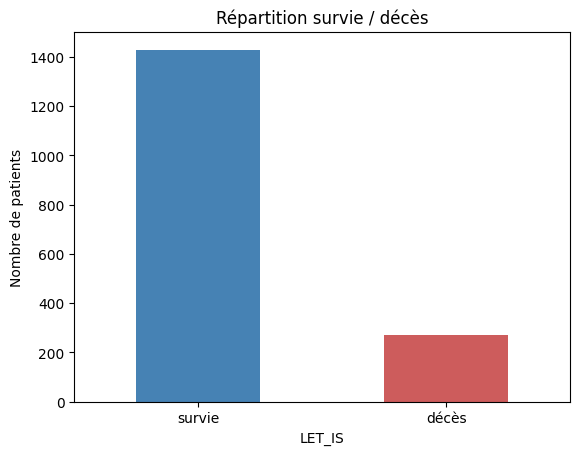

In [6]:
y = df["LET_IS"]

# On binarise la variable letale : 0 = survie, 1 = décès

for i in range(len(y)):
    if y.iloc[i] > 0:
        y.iloc[i] = 1

print("Répartition de la variable LET_IS")
print(y.value_counts().rename({0: "survie", 1: "décès"}))
print("Proportion de décès :", f"{y.mean():.1%}")

y.value_counts().rename({0: "survie", 1: "décès"}).plot(kind="bar", color=["steelblue", "indianred"])
plt.title("Répartition survie / décès")
plt.ylabel("Nombre de patients")
plt.xticks(rotation=0)
plt.show()

**À retenir** : les classes sont **déséquilibrées** (les décès sont une minorité). L'*accuracy* ne suffira donc pas : un modèle qui prédit toujours « survie » aurait un score élevé tout en étant inutile. On utilisera le recall.

L'objectif de notre modèle est de rater le moins de decès possible, nous allons donc porter une attention particulière au recall.

### II.3 - Séparation des variables admission et après 3 jours de soin?

Les colonnes suivent l'ordre chronologique du dossier médical. Certaines ne sont connues que **plus tard** dans l'hospitalisation :

| Groupe | Colonnes | Moment où l'information existe |
|---|---|---|
| Antécédents, ECG, biologie, délai | `AGE` … `TIME_B_S` | à l'admission |
| Traitements des urgences | `NA_KB`, `NOT_NA_KB`, `LID_KB`, `NITR_S` | à l'admission (équipe d'urgence) |
| Douleur récurrente | `R_AB_1_n`, `R_AB_2_n`, `R_AB_3_n` | `_1_` premières heures, `_2_` jour 2, `_3_` jour 3 |
| Opioïdes en soins intensifs | `NA_R_1_n`, `NA_R_2_n`, `NA_R_3_n` | `_1_` premières heures, `_2_` jour 2, `_3_` jour 3 | |
| Anti-inflammatoires en soins intensifs | `NOT_NA_1_n`, `NOT_NA_2_n`, `NOT_NA_3_n` | `_1_` premières heures, `_2_` jour 2, `_3_` jour 3 | |
| Autres traitements en soins intensifs | `LID_S_n`, `B_BLOK_S_n`, `ANT_CA_S_n`, `GEPAR_S_n`, `ASP_S_n`, `TIKL_S_n`, `TRENT_S_n` | pendant le séjour (moment exact à vérifier) |


In [7]:
# Colonnes dont la valeur dépend de ce qui se passe APRÈS l'arrivée (jours 1 à 3)
COLONNES_APRES_ADMISSION = [
    "R_AB_1_n", "R_AB_2_n", "R_AB_3_n",          # récidive de la douleur
    "NA_R_1_n", "NA_R_2_n", "NA_R_3_n",          # opioïdes en soins intensifs
    "NOT_NA_1_n", "NOT_NA_2_n", "NOT_NA_3_n",    # anti-inflammatoires en soins intensifs
]

# Traitements en soins intensifs dont le moment exact est incertain.
# Si STRICT_ADMISSION = True, on les retire aussi du scénario « admission ».

COLONNES_SOINS_INTENSIFS_INCERTAINES = [
    "LID_S_n", "B_BLOK_S_n", "ANT_CA_S_n", "GEPAR_S_n", "ASP_S_n", "TIKL_S_n", "TRENT_S_n",
]

STRICT_ADMISSION = True  # à décider en groupe

a_retirer = list(COLONNES_APRES_ADMISSION)
if STRICT_ADMISSION:
    a_retirer += COLONNES_SOINS_INTENSIFS_INCERTAINES

### II.4 - Construction des dataframe `X_admission` et `X_jour3`

- `X_jour3` : toutes les variables d'entrée (information complète au 3ᵉ jour).
- `X_admission` : les mêmes, moins les colonnes de la cellule précédente.

On garde des **DataFrames** (avec les noms de colonnes) et on ne les convertit pas en tableaux numpy : sans les noms, on ne peut plus interpréter les résultats (importance des variables, SHAP, arbre de décision).

In [8]:
X_jour3 = X_all.copy()
X_admission = X_all.drop(columns=a_retirer)

print("X_jour3     :", X_jour3.shape)
print("X_admission :", X_admission.shape)
print("Colonnes retirées pour l'admission :", len(a_retirer))

X_jour3     : (1700, 111)
X_admission : (1700, 95)
Colonnes retirées pour l'admission : 16


### II.5 - Définition des types de variables de `X_admission` et `X_jour3`

On cherche a donnée un type chacune des variables qui vont nous servir à entrainer le modèle. On distingue 3 types de variables :
- `binaire` pour les variables binaire
- `ordinal` (on place le seuil ordinale à 10)
- `continue`

On affiche également le pourcentage manquant pour chaque colonne

In [9]:
SEUIL_ORDINALE = 10  # au plus 10 modalités entières distinctes -> ordinale

def type_variable(s):
    """Classe une colonne en 'binaire', 'ordinale' ou 'continue' (NaN ignorés)."""
    valeurs = s.dropna().unique()
    if len(valeurs) <= 2:
        return "binaire"
    if np.all(valeurs == np.round(valeurs)) and len(valeurs) <= SEUIL_ORDINALE:
        return "ordinale"
    return "continue"

def resume_par_type(X):
    return pd.DataFrame({
        "type": X.apply(type_variable),
        "nb_modalites": X.nunique(),
        "min": X.min(),
        "max": X.max(),
        "moyenne": X.mean(),
        "% manquants": X.isna().mean() * 100,
    })

resume_all = resume_par_type(X_all)

print(resume_all["type"].value_counts())

for t in ["binaire", "ordinale", "continue"]:
    print(f"\n=== Variables {t}s ===")
    display(resume_all[resume_all["type"] == t].drop(columns="type"))


type
binaire     78
ordinale    21
continue    12
Name: count, dtype: int64

=== Variables binaires ===


,nb_modalites,min,max,moyenne,% manquants
SEX,2,0.0,1.0,0.626471,0.000000
IBS_NASL,2,0.0,1.0,0.375000,95.764706
SIM_GIPERT,2,0.0,1.0,0.033688,0.470588
nr_11,2,0.0,1.0,0.025015,1.235294
nr_01,2,0.0,1.0,0.002382,1.235294
...,...,...,...,...,...
ANT_CA_S_n,2,0.0,1.0,0.666864,0.764706
GEPAR_S_n,2,0.0,1.0,0.714795,1.000000
ASP_S_n,2,0.0,1.0,0.743910,1.000000
TIKL_S_n,2,0.0,1.0,0.017815,0.941176



=== Variables ordinales ===


,nb_modalites,min,max,moyenne,% manquants
INF_ANAM,4,0.0,3.0,0.554835,0.235294
STENOK_AN,7,0.0,6.0,2.316186,6.235294
FK_STENOK,5,0.0,4.0,1.205286,4.294118
IBS_POST,3,0.0,2.0,1.160703,3.000000
GB,4,0.0,3.0,1.393258,0.529412
DLIT_AG,8,0.0,7.0,3.340220,14.588235
ZSN_A,5,0.0,4.0,0.194411,3.176471
ant_im,5,0.0,4.0,1.570810,4.882353
lat_im,5,0.0,4.0,0.861728,4.705882
inf_im,5,0.0,4.0,1.014815,4.705882



=== Variables continues ===


,nb_modalites,min,max,moyenne,% manquants
AGE,62,26.00,92.00,61.856974,0.470588
S_AD_KBRIG,30,0.00,260.00,136.907051,63.294118
D_AD_KBRIG,21,0.00,190.00,81.394231,63.294118
S_AD_ORIT,32,0.00,260.00,134.588276,15.705882
D_AD_ORIT,20,0.00,190.00,82.749477,15.705882
K_BLOOD,51,2.30,8.20,4.191422,21.823529
NA_BLOOD,40,117.00,169.00,136.550943,22.058824
ALT_BLOOD,69,0.03,3.00,0.481455,16.705882
AST_BLOOD,58,0.04,2.15,0.263717,16.764706
KFK_BLOOD,4,1.20,3.60,2.000000,99.764706


### II.6 Valeur manquante par patient

On affiche ici le pourcentage de valeur manquant par patient (par ligne)

In [10]:
# Pourcentage de valeurs manquantes pour chaque patient (chaque ligne de X_all)

resume_patient = (
    X_all.isna().mean(axis=1)
    .mul(100)
    .round(2)
    .rename("% manquants")
    .to_frame()
)

display(resume_patient.head())

,% manquants
ID,
1,8.11
2,2.70
3,2.70
4,8.11
5,2.70


### II.7 Étude des données sur les différentes causes de decès / survivant

In [11]:
n_surv, n_deces = (y == 0).sum(), (y == 1).sum()
print(f"Survie : {n_surv} ({n_surv/len(y):.1%}) | Décès : {n_deces} ({n_deces/len(y):.1%})")
print(f"Ratio : 1 décès pour {n_surv/n_deces:.1f} survivants")

Survie : 1429 (84.1%) | Décès : 271 (15.9%)
Ratio : 1 décès pour 5.3 survivants


Cause de décès (sur la database avant la bianarisation de le colonnes "LET_IS")

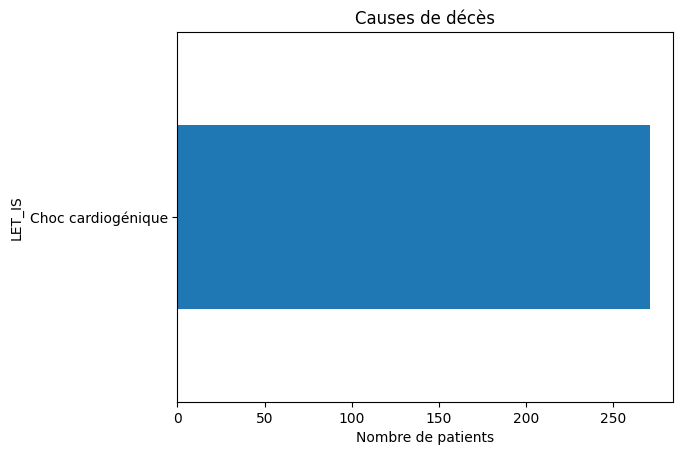

In [12]:
causes = {1: "Choc cardiogénique", 2: "Œdème pulmonaire", 3: "Rupture myocardique",
          4: "Aggravation IC", 5: "Thromboembolie", 6: "Asystolie", 7: "Fibrillation ventriculaire"}
df.loc[df["LET_IS"] > 0, "LET_IS"].map(causes).value_counts().plot(kind="barh")
plt.xlabel("Nombre de patients"); plt.title("Causes de décès"); plt.show()

## III - Séparation du jeu de donnée (train/test) et étude des données

On réalise un étude des données sur le jeu de donnée train pour éviter le dataleak du jeu de données test. L'objectif de cette partie est de comprendre que sont les données qui sont intéressante pour notre analyse.

### III.1 - Séparation du jeu de données en train / test

In [13]:
from sklearn.model_selection import train_test_split

SEED = 42  # fixe le découpage : tout le groupe obtient les mêmes patients dans le train et le test

# 1. On sépare les PATIENTS (leurs identifiants), pas les tableaux.
#    Ainsi X_admission et X_jour3 ont exactement les mêmes patients de test.
idx_train, idx_test = train_test_split(
    y.index,
    test_size=0.2,    # 20 % des patients pour le test
    stratify=y,       # même proportion de décès dans le train et le test
    random_state=SEED,
)

# 2. On applique ce découpage aux deux scénarios et à la cible
X_adm_train, X_adm_test = X_admission.loc[idx_train], X_admission.loc[idx_test]
X_j3_train,  X_j3_test  = X_jour3.loc[idx_train],     X_jour3.loc[idx_test]
y_train, y_test = y.loc[idx_train], y.loc[idx_test]

# 3. Vérifications
print(f"Train : {len(idx_train)} patients, {y_train.sum()} décès ({y_train.mean():.1%})")
print(f"Test  : {len(idx_test)} patients, {y_test.sum()} décès ({y_test.mean():.1%})")

assert set(idx_train).isdisjoint(idx_test), "Des patients sont à la fois dans le train et le test"
assert X_adm_train.index.equals(X_j3_train.index) and X_adm_test.index.equals(X_j3_test.index)

Train : 1360 patients, 217 décès (16.0%)
Test  : 340 patients, 54 décès (15.9%)


### III.2 - Études des données (exemple)

Ici nous allons chercher à visualiser les données continue, pour identifier cette qui sont correlé entre elles ainsi que celle qui diffère entre les patients survivant ou décédés. L'objectif ici est d'isoler les données qui vont nous permettre d'entrainer le modèle.

KFK_BLOOD     99.7
S_AD_KBRIG    63.5
AST_BLOOD     16.9
ALT_BLOOD     16.8
S_AD_ORIT     16.2
D_AD_ORIT     16.2
ROE           12.4
L_BLOOD        7.6
AGE            0.4


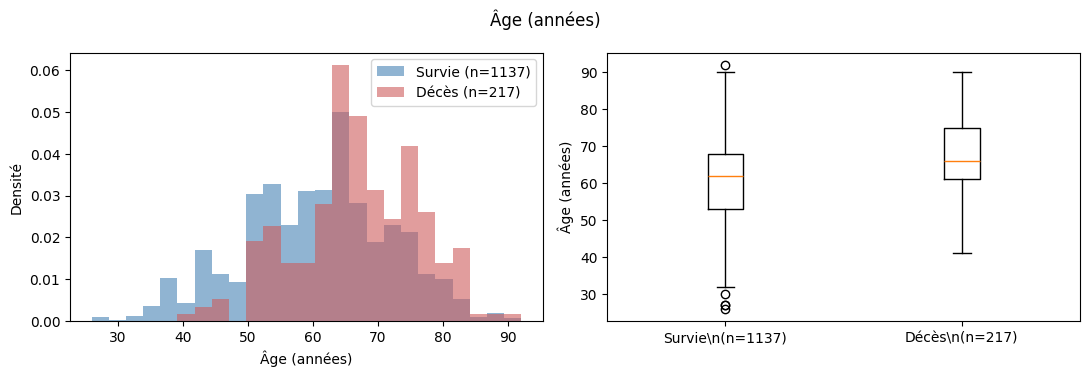

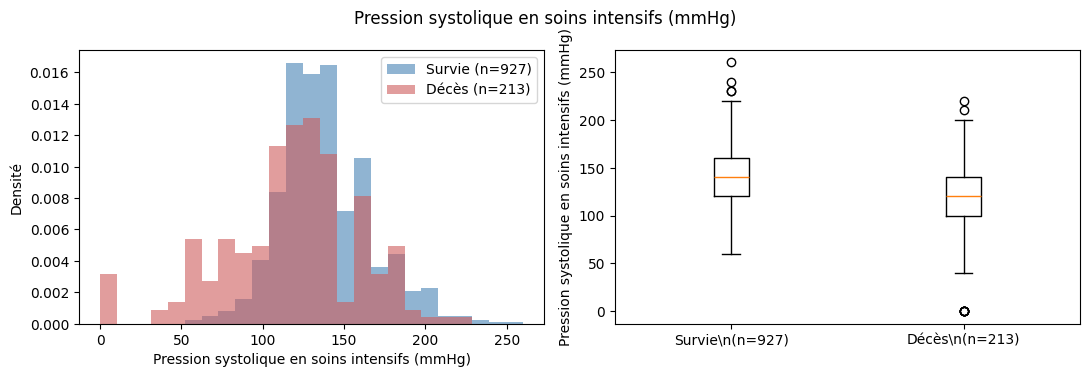

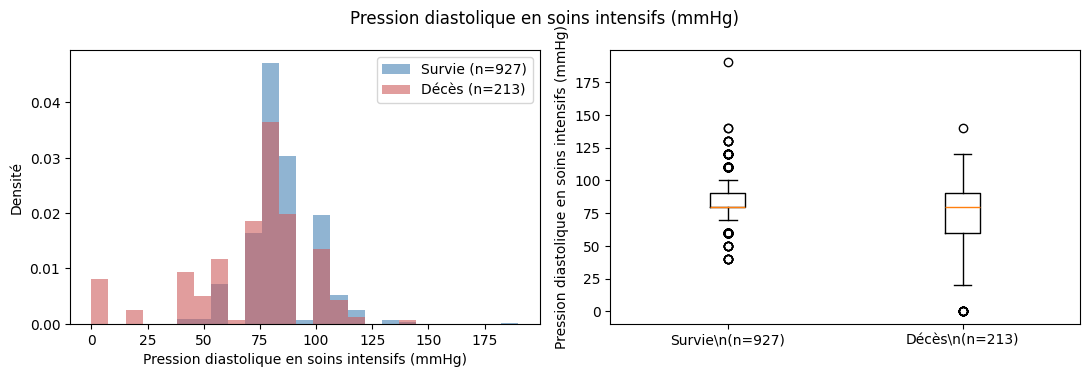

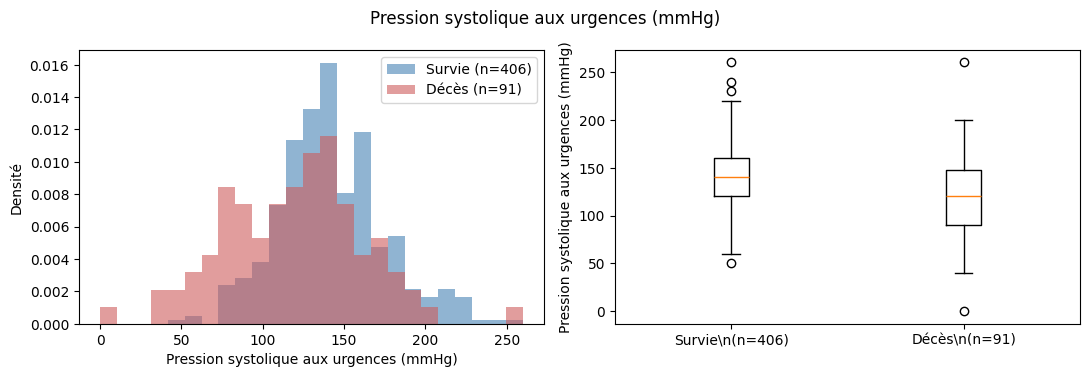

/usr/local/lib/python3.13/dist-packages/numpy/lib/_histograms_impl.py:902: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges


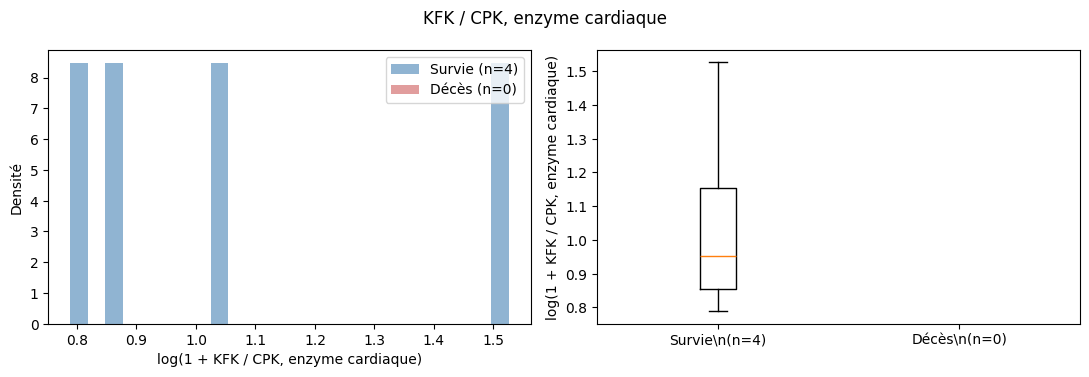

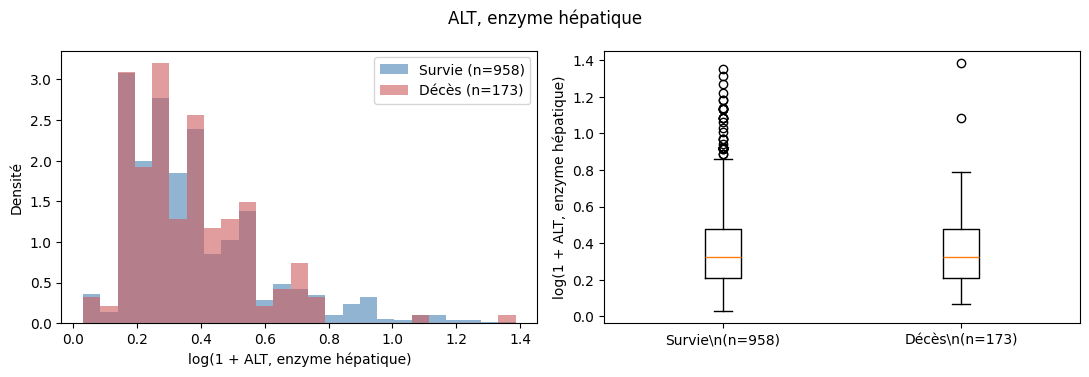

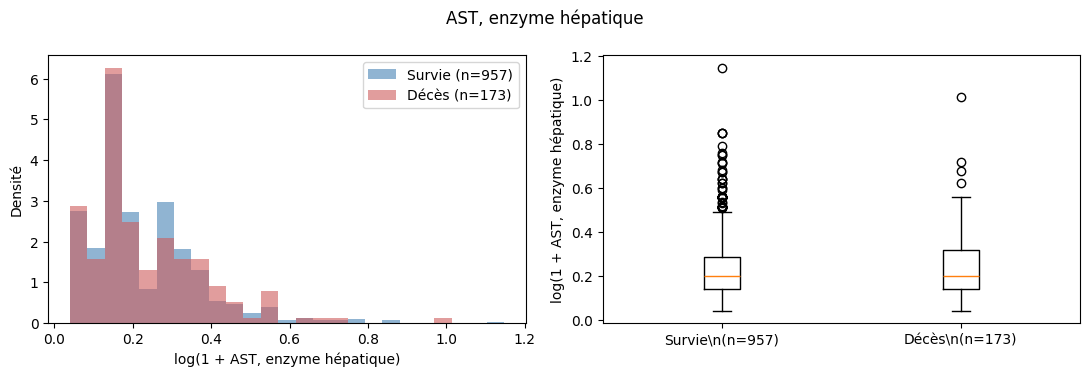

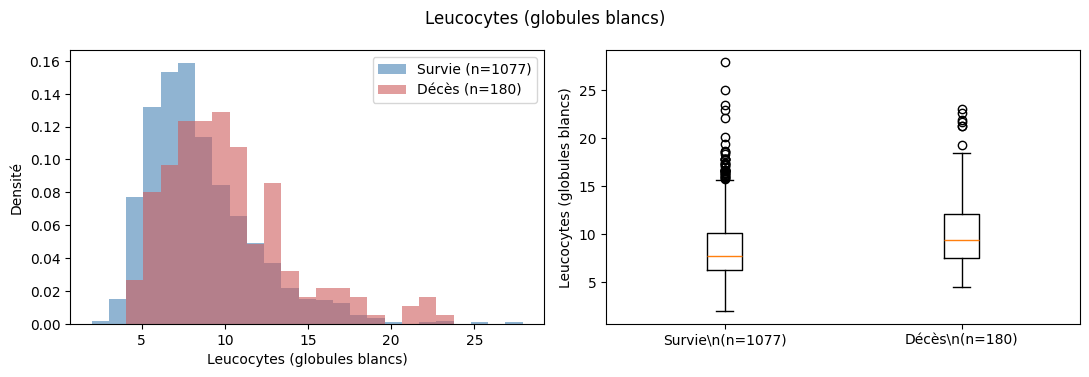

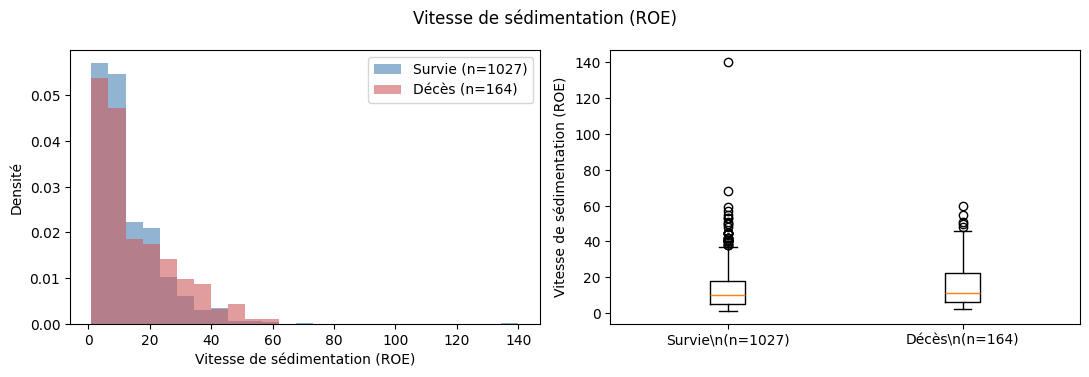

groupe            Décès  Survie
AGE        count  217.0  1137.0
           25%     61.0    53.0
           50%     66.0    62.0
           75%     75.0    68.0
S_AD_ORIT  count  213.0   927.0
           25%    100.0   120.0
           50%    120.0   140.0
           75%    140.0   160.0
D_AD_ORIT  count  213.0   927.0
           25%     60.0    80.0
           50%     80.0    80.0
           75%     90.0    90.0
S_AD_KBRIG count   91.0   406.0
           25%     90.0   120.0
           50%    120.0   140.0
           75%    147.5   160.0
KFK_BLOOD  count    0.0     4.0
           25%      NaN     1.3
           50%      NaN     1.6
           75%      NaN     2.2
ALT_BLOOD  count  173.0   958.0
           25%      0.2     0.2
           50%      0.4     0.4
           75%      0.6     0.6
AST_BLOOD  count  173.0   957.0
           25%      0.2     0.2
           50%      0.2     0.2
           75%      0.4     0.3
L_BLOOD    count  180.0  1077.0
           25%      7.5     6.3
        

In [14]:
# Tableau d'exploration : variables du jour 3 + groupe (survie / décès), train uniquement
exploration = X_j3_train.copy()
exploration["groupe"] = y_train.map({0: "Survie", 1: "Décès"})

COULEURS = {"Survie": "steelblue", "Décès": "indianred"}

# colonne : (libellé, échelle logarithmique ?)
# Les unités sont à vérifier dans la description UCI.
VARIABLES = {
    "AGE":        ("Âge (années)", False),
    "S_AD_ORIT":  ("Pression systolique en soins intensifs (mmHg)", False),
    "D_AD_ORIT":  ("Pression diastolique en soins intensifs (mmHg)", False),
    "S_AD_KBRIG": ("Pression systolique aux urgences (mmHg)", False),
    "KFK_BLOOD":  ("KFK / CPK, enzyme cardiaque", True),
    "ALT_BLOOD":  ("ALT, enzyme hépatique", True),
    "AST_BLOOD":  ("AST, enzyme hépatique", True),
    "L_BLOOD":    ("Leucocytes (globules blancs)", False),
    "ROE":        ("Vitesse de sédimentation (ROE)", False),
}

def comparer(col, libelle, log=False):
    """Histogramme + boxplot de `col`, survivants contre décédés."""
    donnees = {g: exploration.loc[exploration["groupe"] == g, col].dropna()
               for g in ["Survie", "Décès"]}
    if log:  # variables très asymétriques : on passe à log(1 + x) pour y voir quelque chose
        donnees = {g: np.log1p(v) for g, v in donnees.items()}
    xlabel = f"log(1 + {libelle})" if log else libelle

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))

    # Histogramme : mêmes classes pour les deux groupes, et density=True car
    # les décès sont beaucoup moins nombreux (sinon leur barre serait invisible)
    tout = np.concatenate([v.values for v in donnees.values()])
    bins = np.histogram_bin_edges(tout, bins=25)
    for g, v in donnees.items():
        ax1.hist(v, bins=bins, density=True, alpha=0.6, color=COULEURS[g],
                 label=f"{g} (n={len(v)})")
    ax1.set_xlabel(xlabel); ax1.set_ylabel("Densité"); ax1.legend()

    # Boxplot avec l'effectif de chaque groupe
    ax2.boxplot([donnees["Survie"], donnees["Décès"]], showfliers=True)
    ax2.set_xticklabels([f"{g}\\n(n={len(donnees[g])})" for g in ["Survie", "Décès"]])
    ax2.set_ylabel(xlabel)

    fig.suptitle(libelle)
    plt.tight_layout()
    plt.show()

# 1. Regarder d'abord combien de valeurs manquantes (et donc combien de patients exploitables)
cols = list(VARIABLES)
print((exploration[cols].isna().mean() * 100).round(1).sort_values(ascending=False).to_string())

# 2. Un couple de graphiques par variable
for col, (libelle, log) in VARIABLES.items():
    comparer(col, libelle, log)

# 3. Tableau récapitulatif : médiane et quartiles par groupe
resume = exploration.groupby("groupe")[cols].describe().T.loc[(slice(None), ["count", "25%", "50%", "75%"]), :]
print(resume.round(1))

### Objectif

Nous cherchons à savoir si certaines *features* se comportent différemment chez les patients décédés et chez les survivants.

Pour chaque variable, nous traçons un histogramme (forme de la distribution) et un boxplot (comparaison des médianes et des dispersions). Quatre choix méthodologiques sont à noter :

- **Jeu d'entraînement uniquement** : les graphiques servent à prendre des décisions de preprocessing. Utiliser le jeu de test pour cela fausserait l'évaluation finale.
- **Histogrammes normalisés (densité)** : les décès sont beaucoup moins nombreux que les survies. Sans normalisation, la distribution des décès serait invisible.

- **Effectif affiché** sur chaque graphique : la comparaison n'a de sens que si chaque groupe contient assez de patients.

### Valeurs manquantes

Le pourcentage de valeurs manquantes varie fortement d'une variable à l'autre : [À REMPLIR : % pour AGE, pression, KFK, ALT/AST, leucocytes]. Une valeur manquante signifie souvent qu'un examen n'a pas été réalisé, et pas seulement qu'une saisie a été oubliée. Pour la variable [À REMPLIR : la plus incomplète], seuls [À REMPLIR : n] patients sont renseignés dans le train, dont [À REMPLIR : n] décédés : la comparaison est [possible / peu fiable / impossible], et nous [ne l'interprétons pas / l'interprétons avec prudence].

### Âge

Les patients décédés sont plus âgés que les survivants : l'âge médian est de 66 ans chez les décédés contre 62 ans chez les survivants. Les deux distributions se chevauchent  modérément.
L'Âge est une caractéristique interessante pour notre modèle.
Nous disposons également de cette valeur pour le cas des patients admis au urgence, nous retrouvons un écart à la médiane qui est similaire.

### Pression systolique

À l'entrée en soins intensifs, la pression systolique médiane est de 120 mmHg chez les survivants et de 100 mmHg chez les décédés. La différence est nette.
La pression systolique est une caractéristique interessante pour notre modèle.
Nous disposons également de cette valeur pour le cas des patients admis au urgence, nous retrouvons un écart à la médiane qui est similaire.

### KFK (enzyme cardiaque)

La KFK (CPK) est une enzyme libérée par le muscle cardiaque lorsqu'il est lésé : elle est généralement associée à l'étendue de la nécrose. La variable est renseignée pour trop peu de patient elle n'est donc pas intéressante pour notre analyse.

### ALT et AST (enzymes hépatiques)

Ces enzymes reflètent l'état du foie, mais elles augmentent aussi lors de lésions cardiaques. Leurs distributions est similaire pour les cas de décès et de survie. Ces variables ne sont donc pas interessante pour notre analyse.

### Leucocytes

Les leucocytes (globules blancs) augmentent en cas de réaction inflammatoire. Le nombre médian est de 7,8 chez les survivants et de 9,4 chez les décédés. Cette caractéristique est donc intéressante pour notre analyse.

### Valeurs extrêmes

Pour l'instant nous avons pris la decision de ne pas supprimer les valeurs extrèmes, car elles peuvent correspondre à des cas réel de patient. Nous verrons par la suite si il intéressant de les traiter.

### Synthèse

- Les variables qui semblent le mieux distinguer les deux groupes sont age, pression systolique, leucocyte.
- Les variables qui semblent peu discriminantes sont KFK, ALT, AST.
- Une variable à créer lors du *feature engineering* : la pression pulsée (S_AD − D_AD).

### III.3 - Calcul de la matrice de correlation

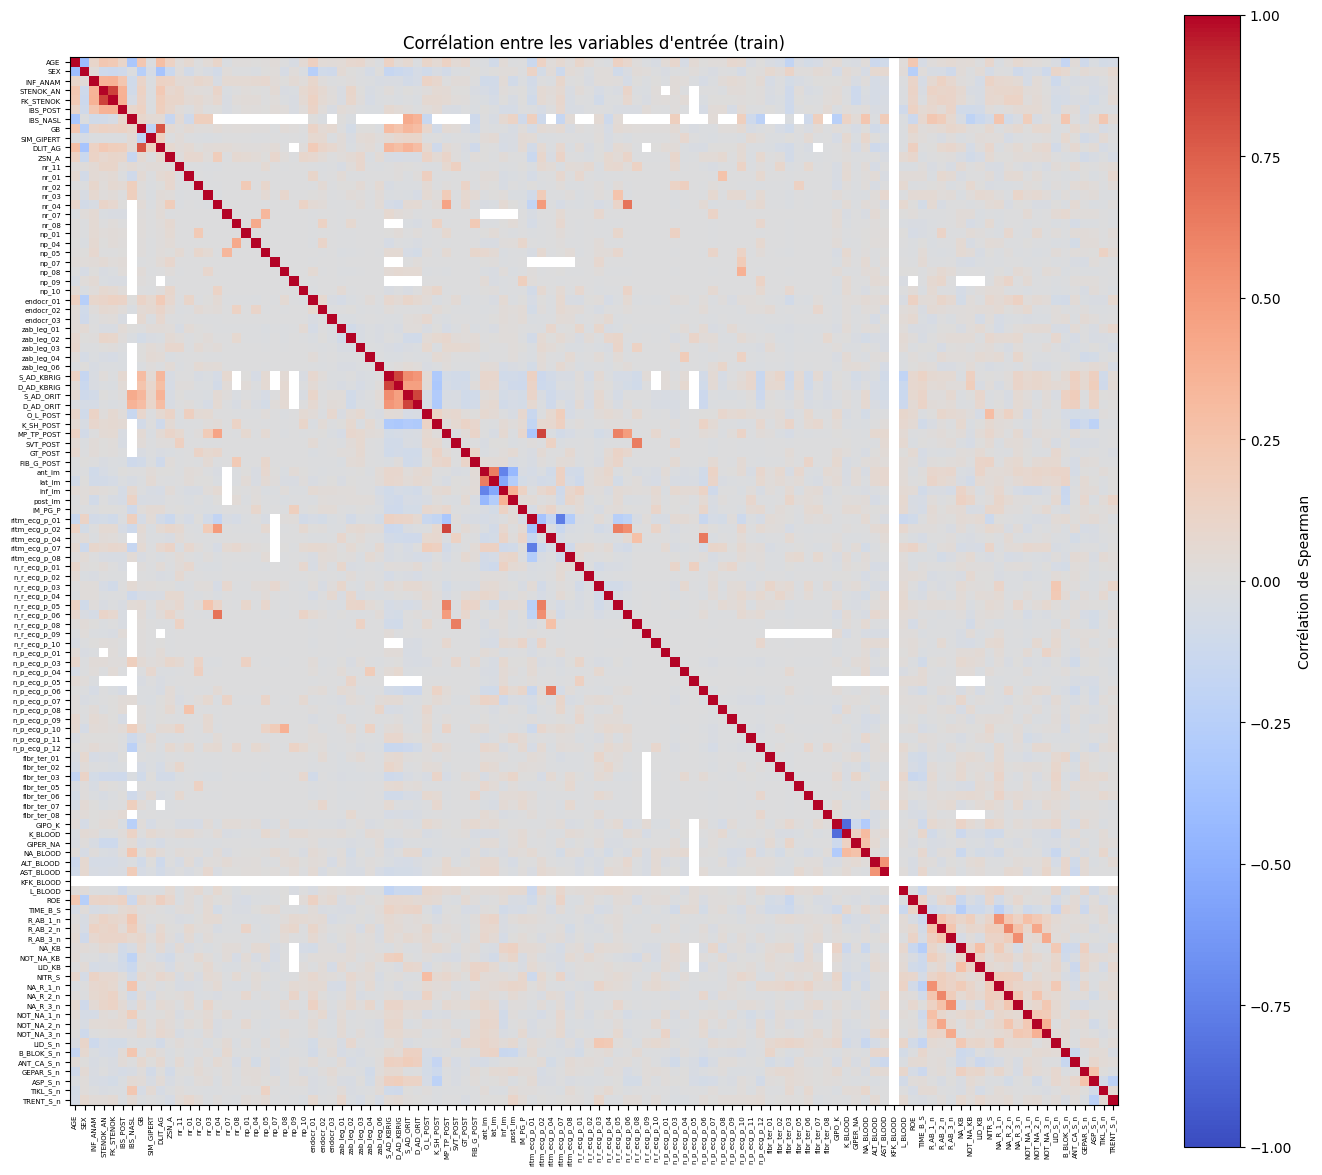

8 paires avec |corrélation| >= 0.7
STENOK_AN      FK_STENOK        0.86
S_AD_ORIT      D_AD_ORIT        0.85
GIPO_K         K_BLOOD         -0.85
S_AD_KBRIG     D_AD_KBRIG       0.84
MP_TP_POST     ritm_ecg_p_02    0.84
GB             DLIT_AG          0.79
ritm_ecg_p_01  ritm_ecg_p_07   -0.77
ant_im         inf_im          -0.74


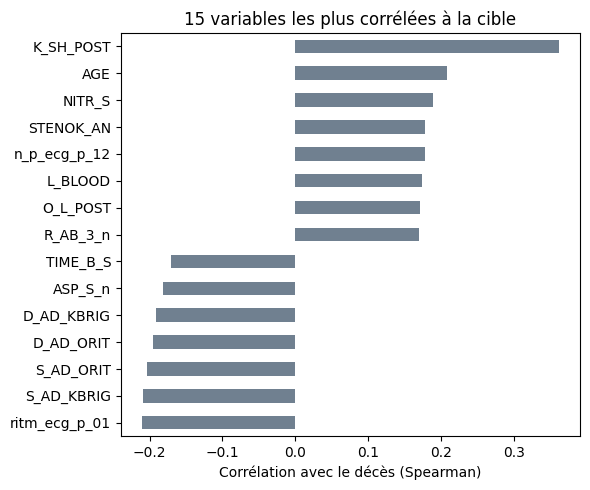

In [15]:
# 1. Données : toutes les features du jour 3, train uniquement.
#    On retire les colonnes constantes (une corrélation avec elles n'est pas définie).
donnees = X_j3_train.copy()
donnees = donnees.loc[:, donnees.nunique() > 1]

# 2. Matrice de corrélation de Spearman, calculée sur les patients où les deux variables sont connues.
#    min_periods : si moins de 30 patients ont les deux valeurs, la corrélation reste vide (NaN).
corr = donnees.corr(method="spearman", min_periods=30)

# 3. Heatmap
fig, ax = plt.subplots(figsize=(14, 12))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=5)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=5)
fig.colorbar(im, ax=ax, label="Corrélation de Spearman")
ax.set_title("Corrélation entre les variables d'entrée (train)")
plt.tight_layout()
plt.show()

# 4. Paires de variables fortement corrélées (on ne garde que le triangle supérieur pour éviter les doublons)
SEUIL = 0.7
haut = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
paires = haut[haut.abs() >= SEUIL].sort_values(key=abs, ascending=False)
print(f"{len(paires)} paires avec |corrélation| >= {SEUIL}")
print(paires.round(2).to_string())

# 5. Corrélation de chaque variable avec la cible (décès)
avec_cible = donnees.apply(lambda col: col.corr(y_train, method="spearman", min_periods=30))
top = avec_cible.reindex(avec_cible.abs().sort_values(ascending=False).index).head(15)

top.sort_values().plot(kind="barh", figsize=(6, 5), color="slategray")
plt.xlabel("Corrélation avec le décès (Spearman)")
plt.title("15 variables les plus corrélées à la cible")
plt.tight_layout()
plt.show()

## IV - Preprocessing des données

### IV.1 - Suppression des colonnes trop vides

**Objectif**

Retirer les variables qui contiennent trop de valeurs manquantes.

Ce traitement est appliqué séparément aux deux jeux de données (**ADM** et **J3**), chacun ayant sa propre liste de colonnes supprimées.

**Choix méthodologiques**

- **Seuil de 40 %** : valeur courante en pratique, qui représente un bon compromis entre conserver de l'information et éviter les colonnes trop pauvres. Ce seuil reste un paramètre ajustable (`SEUIL_NA`).
- **Absence de fuite de données (*data leakage*)** : les colonnes à supprimer sont déterminées à partir du jeu d'entraînement seul.
- **Cohérence des schémas** : une vérification (`assert`) contrôle que le jeu d'entraînement et le jeu de test ont exactement les mêmes colonnes, dans le même ordre, ce qui est nécessaire pour les étapes suivantes (imputation, standardisation, modélisation).

In [16]:
# --- Paramètres ---
SEUIL_NA = 0.4  # on supprime les colonnes avec plus de 40 % de valeurs manquantes
NA_DEGUISES = ["", "?", "unknown", "N/A"]

def supprimer_colonnes_vides(X_train, X_test, seuil=SEUIL_NA, nom=""):
    """Détermine les colonnes trop vides sur X_train, puis les retire de X_train et X_test."""
    # Harmonisation des NA déguisés
    X_train = X_train.replace(NA_DEGUISES, np.nan)
    X_test = X_test.replace(NA_DEGUISES, np.nan)

    # Taux de NA calculé sur le TRAIN uniquement
    taux_na = X_train.isna().mean().sort_values(ascending=False)
    cols_a_supprimer = taux_na[taux_na > seuil].index.tolist()

    # Récapitulatif
    print(f"===== {nom} =====")
    print("Taux de NA (train) pour les colonnes concernées :")
    print((taux_na[taux_na > 0] * 100).round(2).to_string(), "\n")
    print(f"Colonnes supprimées ({len(cols_a_supprimer)}) : {cols_a_supprimer}")

    # Application identique au train et au test
    X_train_clean = X_train.drop(columns=cols_a_supprimer)
    X_test_clean = X_test.drop(columns=cols_a_supprimer, errors="ignore")

    print(f"Train : {X_train.shape} -> {X_train_clean.shape}")
    print(f"Test  : {X_test.shape} -> {X_test_clean.shape}\n")

    # Sécurité : mêmes colonnes, dans le même ordre
    assert list(X_train_clean.columns) == list(X_test_clean.columns), \
        f"{nom} : les colonnes de train et de test ne correspondent pas"

    return X_train_clean, X_test_clean, cols_a_supprimer


# --- Application aux deux jeux de données ---
X_adm_train_clean, X_adm_test_clean, cols_supp_adm = supprimer_colonnes_vides(
    X_adm_train, X_adm_test, nom="ADM"
)

X_j3_train_clean, X_j3_test_clean, cols_supp_j3 = supprimer_colonnes_vides(
    X_j3_train, X_j3_test, nom="J3"
)

===== ADM =====
Taux de NA (train) pour les colonnes concernées :
KFK_BLOOD        99.71
IBS_NASL         95.29
D_AD_KBRIG       63.46
S_AD_KBRIG       63.46
NOT_NA_KB        40.22
LID_KB           39.63
NA_KB            38.24
GIPER_NA         22.87
NA_BLOOD         22.87
K_BLOOD          22.65
GIPO_K           22.50
AST_BLOOD        16.91
ALT_BLOOD        16.84
S_AD_ORIT        16.18
D_AD_ORIT        16.18
DLIT_AG          14.34
ROE              12.43
ritm_ecg_p_06     9.26
ritm_ecg_p_04     9.26
ritm_ecg_p_01     9.26
ritm_ecg_p_02     9.26
ritm_ecg_p_08     9.26
ritm_ecg_p_07     9.26
L_BLOOD           7.57
TIME_B_S          7.35
n_r_ecg_p_10      6.91
n_r_ecg_p_05      6.91
n_r_ecg_p_01      6.91
n_r_ecg_p_02      6.91
n_r_ecg_p_08      6.91
n_r_ecg_p_09      6.91
n_p_ecg_p_09      6.91
n_p_ecg_p_08      6.91
n_p_ecg_p_07      6.91
n_p_ecg_p_06      6.91
n_p_ecg_p_05      6.91
n_p_ecg_p_12      6.91
n_p_ecg_p_11      6.91
n_p_ecg_p_10      6.91
n_p_ecg_p_04      6.91
n_p_ecg_p_01  

### IV.2 - Imputation des valeurs manquante

Cette partie permet de remplacer les valeurs manquantes dans chacune des colonnes par une valeur que introduit le moins de biais possible. Tout en permettant au dataset d'être utlisé avec des modèles qui ne supporte pas les valeurs manquantes (ex SVM). Elle n'est donc pas forcément necessaire en fonction des méthodes qui vont être utilisé.
- On utilise la méthode de la médiane pour les variables continues
- On utlise la méthode des modes pour les variables binaire et ordinales

In [17]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

def imputer_mediane_mode(X_train, X_test, resume, nom=""):
    """Médiane pour les variables continues, mode pour les binaires et ordinales.
    L'imputeur est ajusté sur le train uniquement, puis appliqué au train et au test."""
    # On ne garde que les colonnes encore présentes après l'étape IV.1
    cols_cont = [c for c in X_train.columns if resume.loc[c, "type"] == "continue"]
    cols_mode = [c for c in X_train.columns if resume.loc[c, "type"] in ("binaire", "ordinale")]

    imputeur = ColumnTransformer(
        transformers=[
            ("mediane", SimpleImputer(strategy="median"), cols_cont),
            ("mode", SimpleImputer(strategy="most_frequent"), cols_mode),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")

    X_train_imp = imputeur.fit_transform(X_train)   # fit sur le train uniquement
    X_test_imp = imputeur.transform(X_test)         # simple application au test

    # Retour à l'ordre d'origine des colonnes
    X_train_imp = X_train_imp[X_train.columns]
    X_test_imp = X_test_imp[X_train.columns]

    print(f"===== {nom} =====")
    print(f"Continues (médiane) : {len(cols_cont)} | Binaires/ordinales (mode) : {len(cols_mode)}")
    print(f"NA restants - train : {X_train_imp.isna().sum().sum()} | test : {X_test_imp.isna().sum().sum()}\n")

    return X_train_imp, X_test_imp, imputeur


# --- Application aux deux jeux de données (après la suppression des colonnes vides) ---
X_adm_train_imp, X_adm_test_imp, imp_adm = imputer_mediane_mode(
    X_adm_train_clean, X_adm_test_clean, resume_all, nom="ADM"
)
X_j3_train_imp, X_j3_test_imp, imp_j3 = imputer_mediane_mode(
    X_j3_train_clean, X_j3_test_clean, resume_all, nom="J3"
)

===== ADM =====
Continues (médiane) : 9 | Binaires/ordinales (mode) : 81
NA restants - train : 0 | test : 0

===== J3 =====
Continues (médiane) : 9 | Binaires/ordinales (mode) : 97
NA restants - train : 0 | test : 0



### IV.3 - Standardisation des colonnes continues

**Objectif**

Mettre les variables continues à la même échelle (moyenne 0, écart-type 1). Sans cela, les variables aux grandes valeurs dominent les modèles sensibles à l'échelle (régression logistique, SVM, KNN, réseaux de neurones), et la régularisation (L1/L2, Elastic Net) pénalise les coefficients de façon inégale.

**Méthode**

- Utilisation de `StandardScaler` sur les variables de type **continue** uniquement (repérées grâce au tableau des types).
- Les variables **binaires** et **ordinales** restent inchangées, car les standardiser ferait perdre leur interprétation.
- Le scaler est **ajusté sur le jeu d'entraînement uniquement**, puis appliqué au jeu de test, afin d'éviter toute fuite de données.
- Traitement appliqué séparément aux jeux **ADM** et **J3**.

**Vérification**

Sur le train, les variables continues ont une moyenne proche de 0 et un écart-type de 1. Sur le test, les valeurs sont proches mais pas exactes, ce qui est normal.

**Étape suivante** : gestion du déséquilibre de classes (poids de classes ou SMOTE, appliqué uniquement dans le pipeline d'entraînement).

In [18]:
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer

def standardiser_continues(X_train, X_test, resume, nom=""):
    """Standardise uniquement les variables continues (moyenne 0, écart-type 1).
    Le scaler est ajusté sur le train uniquement, puis appliqué au test."""
    cols_cont = [c for c in X_train.columns if resume.loc[c, "type"] == "continue"]

    scaler = ColumnTransformer(
        transformers=[("scale", StandardScaler(), cols_cont)],
        remainder="passthrough",              # binaires et ordinales inchangées
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")

    X_train_sc = scaler.fit_transform(X_train)   # fit sur le train uniquement
    X_test_sc = scaler.transform(X_test)

    # Retour à l'ordre d'origine des colonnes
    X_train_sc = X_train_sc[X_train.columns]
    X_test_sc = X_test_sc[X_train.columns]

    print(f"===== {nom} =====")
    print(f"Variables standardisées : {len(cols_cont)}")
    # Correction ici : on applique round() global de Python sur le max
    max_mean = round(X_train_sc[cols_cont].mean().abs().max(), 6)
    unique_std = X_train_sc[cols_cont].std(ddof=0).round(6).unique()[:3]
    print("Train - moyenne ~0 :", max_mean,
          "| écart-type ~1 :", unique_std, "\n")

    return X_train_sc, X_test_sc, scaler


X_adm_train_sc, X_adm_test_sc, scaler_adm = standardiser_continues(
    X_adm_train_imp, X_adm_test_imp, resume_all, nom="ADM"
)
X_j3_train_sc, X_j3_test_sc, scaler_j3 = standardiser_continues(
    X_j3_train_imp, X_j3_test_imp, resume_all, nom="J3"
)

===== ADM =====
Variables standardisées : 9
Train - moyenne ~0 : 0.0 | écart-type ~1 : [1.] 

===== J3 =====
Variables standardisées : 9
Train - moyenne ~0 : 0.0 | écart-type ~1 : [1.] 



### IV.4 - Desequilibre des classes

In [19]:
from sklearn.utils.class_weight import compute_class_weight

def poids_de_classes(y_train, nom=""):
    """Affiche la répartition des classes et les poids 'balanced' calculés sur le train."""
    classes = np.unique(y_train)
    poids = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)

    resume = pd.DataFrame({
        "effectif": pd.Series(y_train).value_counts().sort_index(),
        "proportion (%)": (pd.Series(y_train).value_counts(normalize=True).sort_index() * 100).round(2),
        "poids balanced": poids.round(3),
    })
    print(f"===== {nom} =====")
    print(resume, "\n")
    return dict(zip(classes, poids))

poids_adm = poids_de_classes(y_train)


=====  =====
        effectif  proportion (%)  poids balanced
LET_IS                                          
0           1143           84.04           0.595
1            217           15.96           3.134 



# V.1 Phase d'apprentissage - Cross Validation

In [20]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from xgboost import XGBClassifier

# Ratio pour le déséquilibre de classes (1429 survies / 271 décès ≈ 5.3)
ratio_classes = (y_train == 0).sum() / (y_train == 1).sum()

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Modèle de base
xgb_base = XGBClassifier(
    scale_pos_weight=ratio_classes,  # compense le déséquilibre
    eval_metric="logloss",
    random_state=SEED
)

# Évaluation en validation croisée sur le train
scores_f1 = cross_val_score(xgb_base, X_adm_train_imp, y_train, cv=cv, scoring="f1")

print(f"F1-scores (5-folds) : {scores_f1.round(3)}")
print(f"F1-score moyen : {scores_f1.mean():.3f} (± {scores_f1.std():.3f})")

F1-scores (5-folds) : [0.621 0.514 0.602 0.558 0.533]
F1-score moyen : 0.566 (± 0.040)


In [21]:
from sklearn.model_selection import RandomizedSearchCV

# Grille d'hyperparamètres à explorer
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 4, 6, 8],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "min_child_weight": [1, 3, 5]
}

search_adm = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_grid,
    n_iter=20,              # nombre de combinaisons testées
    cv=cv,                  # StratifiedKFold
    scoring="f1",           # optimisation ciblée sur le F1-score
    random_state=SEED,
    n_jobs=-1
)

search_adm.fit(X_adm_train_imp, y_train)

print(f"Meilleur F1-score en CV : {search_adm.best_score_:.3f}")
print("Meilleurs hyperparamètres :", search_adm.best_params_)

Meilleur F1-score en CV : 0.597
Meilleurs hyperparamètres : {'subsample': 0.7, 'n_estimators': 300, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.1, 'colsample_bytree': 1.0}


In [22]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, classification_report, confusion_matrix
from sklearn.model_selection import cross_val_predict

# 0. Définir explicitement le meilleur modèle trouvé par la recherche d'hyperparamètres
best_model_adm = search_adm.best_estimator_

# 1. Obtenir les probabilités sur le train (CV) en utilisant le meilleur estimateur trouvé
y_proba_train_cv = cross_val_predict(
    best_model_adm,
    X_adm_train_imp,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

# 2. Calculer la courbe Precision-Recall
precisions, recalls, thresholds = precision_recall_curve(y_train, y_proba_train_cv)

# 3. PLACER LE CODE DU SEUIL MÉDICAL ICI
idx_rappel_cible = np.where(recalls[:-1] >= 0.80)[0]

if len(idx_rappel_cible) > 0:
    # Seuil le plus haut parmi ceux assurant >= 80% de rappel
    seuil_medical = thresholds[idx_rappel_cible[-1]]
    print(f"Seuil sélectionné pour au moins 80 % de rappel : {seuil_medical:.3f}")

    # 4. Évaluation sur le test avec ce seuil
    y_proba_test = best_model_adm.predict_proba(X_adm_test_imp)[:, 1]
    y_pred_medical = (y_proba_test >= seuil_medical).astype(int)

    print("\n===== Performances sur Test avec Seuil Médical =====")
    print("Matrice de confusion :")
    print(confusion_matrix(y_test, y_pred_medical))
    print(classification_report(y_test, y_pred_medical, target_names=["Survie", "Décès"]))
else:
    print("Aucun seuil ne permet d'atteindre 80 % de rappel.")

Seuil sélectionné pour au moins 80 % de rappel : 0.160

===== Performances sur Test avec Seuil Médical =====
Matrice de confusion :
[[229  57]
 [ 11  43]]
              precision    recall  f1-score   support

      Survie       0.95      0.80      0.87       286
       Décès       0.43      0.80      0.56        54

    accuracy                           0.80       340
   macro avg       0.69      0.80      0.71       340
weighted avg       0.87      0.80      0.82       340



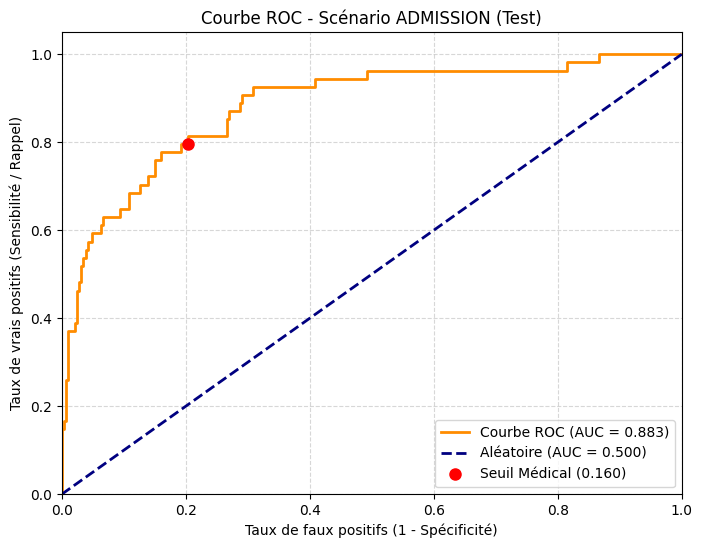

In [23]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# 1. Calculer les probabilités de prédiction pour le jeu de test
y_proba_test = best_model_adm.predict_proba(X_adm_test_imp)[:, 1]

# 2. Calculer le taux de faux positifs (FPR) et le taux de vrais positifs (TPR)
fpr, tpr, thresholds_roc = roc_curve(y_test, y_proba_test)
auc_score = roc_auc_score(y_test, y_proba_test)

# 3. Tracer la courbe ROC
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Courbe ROC (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Aléatoire (AUC = 0.500)')

# Marquer la position du seuil médical choisi (~0.160)
# On trouve l'indice du seuil le plus proche de 0.160
idx_seuil_med = np.argmin(np.abs(thresholds_roc - seuil_medical))
plt.plot(fpr[idx_seuil_med], tpr[idx_seuil_med], 'ro', markersize=8, label=f'Seuil Médical ({seuil_medical:.3f})')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("Taux de faux positifs (1 - Spécificité)")
plt.ylabel("Taux de vrais positifs (Sensibilité / Rappel)")
plt.title("Courbe ROC - Scénario ADMISSION (Test)")
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

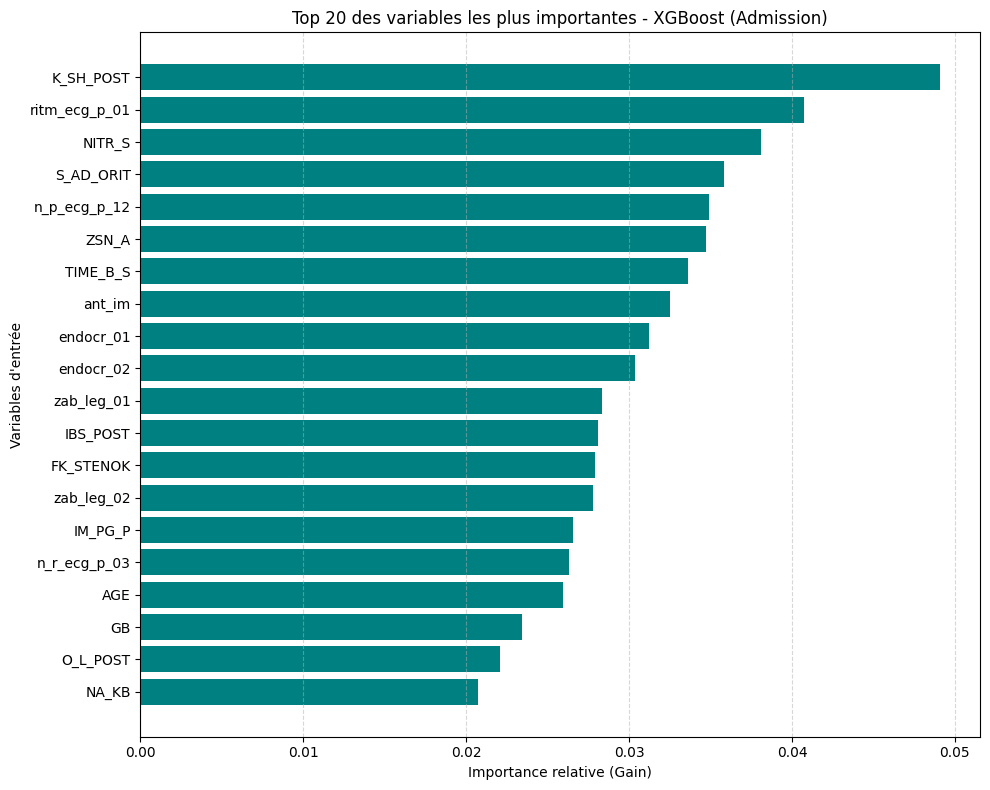

,Variable,Importance
35,K_SH_POST,0.049090
45,ritm_ecg_p_01,0.040710
89,NITR_S,0.038075
32,S_AD_ORIT,0.035851
70,n_p_ecg_p_12,0.034893
9,ZSN_A,0.034694
86,TIME_B_S,0.033620
40,ant_im,0.032543
24,endocr_01,0.031232
25,endocr_02,0.030381


In [24]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Récupérer l'importance des variables depuis le meilleur modèle XGBoost
importances = best_model_adm.feature_importances_
features = X_adm_train_clean.columns

# 2. Créer un DataFrame pour faciliter le tri et la visualisation
feat_imp_df = pd.DataFrame({
    'Variable': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# 3. Afficher les 20 variables les plus importantes
plt.figure(figsize=(10, 8))
plt.barh(feat_imp_df['Variable'].head(20)[::-1], feat_imp_df['Importance'].head(20)[::-1], color='teal')
plt.xlabel('Importance relative (Gain)')
plt.ylabel('Variables d\'entrée')
plt.title('Top 20 des variables les plus importantes - XGBoost (Admission)')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Afficher le tableau des 10 variables les plus importantes sous forme de texte
display(feat_imp_df.head(10))

In [25]:
from sklearn.svm import SVC
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import classification_report, confusion_matrix

# 1. Grille d'hyperparamètres pour le SVM
svm_param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1],
    'kernel': ['rbf', 'linear', 'sigmoid'],
    'class_weight': ['balanced', None]
}

# 2. Initialisation du SVM (on utilise les données standardisées)
svm_base = SVC(probability=True, random_state=SEED)

# 3. Recherche des meilleurs hyperparamètres par CV
search_svm = RandomizedSearchCV(
    estimator=svm_base,
    param_distributions=svm_param_grid,
    n_iter=20,
    cv=cv,
    scoring='f1',
    random_state=SEED,
    n_jobs=-1
)

# Attention : utilisation indispensable des données standardisées (_sc) pour le SVM
search_svm.fit(X_adm_train_sc, y_train)
best_model_svm = search_svm.best_estimator_

# 4. Prédiction et évaluation sur le jeu de test
y_pred_svm = best_model_svm.predict(X_adm_test_sc)

print(f"Meilleur F1-score en CV pour SVM : {search_svm.best_score_:.3f}")
print("Meilleurs hyperparamètres SVM :", search_svm.best_params_)

print("\n===== Performances sur Test (Scénario ADMISSION - SVM) =====")
print(classification_report(y_test, y_pred_svm, target_names=["Survie", "Décès"]))
print("Matrice de confusion SVM :")
print(confusion_matrix(y_test, y_pred_svm))

print("\n===== Rappel : Performances de XGBoost (Seuil Médical 0.160) =====")
print(classification_report(y_test, y_pred_medical, target_names=["Survie", "Décès"]))
print("Matrice de confusion XGBoost (Médical) :")
print(confusion_matrix(y_test, y_pred_medical))

Meilleur F1-score en CV pour SVM : 0.541
Meilleurs hyperparamètres SVM : {'kernel': 'linear', 'gamma': 0.01, 'class_weight': 'balanced', 'C': 10}

===== Performances sur Test (Scénario ADMISSION - SVM) =====
              precision    recall  f1-score   support

      Survie       0.92      0.77      0.84       286
       Décès       0.34      0.65      0.45        54

    accuracy                           0.75       340
   macro avg       0.63      0.71      0.64       340
weighted avg       0.83      0.75      0.77       340

Matrice de confusion SVM :
[[219  67]
 [ 19  35]]

===== Rappel : Performances de XGBoost (Seuil Médical 0.160) =====
              precision    recall  f1-score   support

      Survie       0.95      0.80      0.87       286
       Décès       0.43      0.80      0.56        54

    accuracy                           0.80       340
   macro avg       0.69      0.80      0.71       340
weighted avg       0.87      0.80      0.82       340

Matrice de confusion

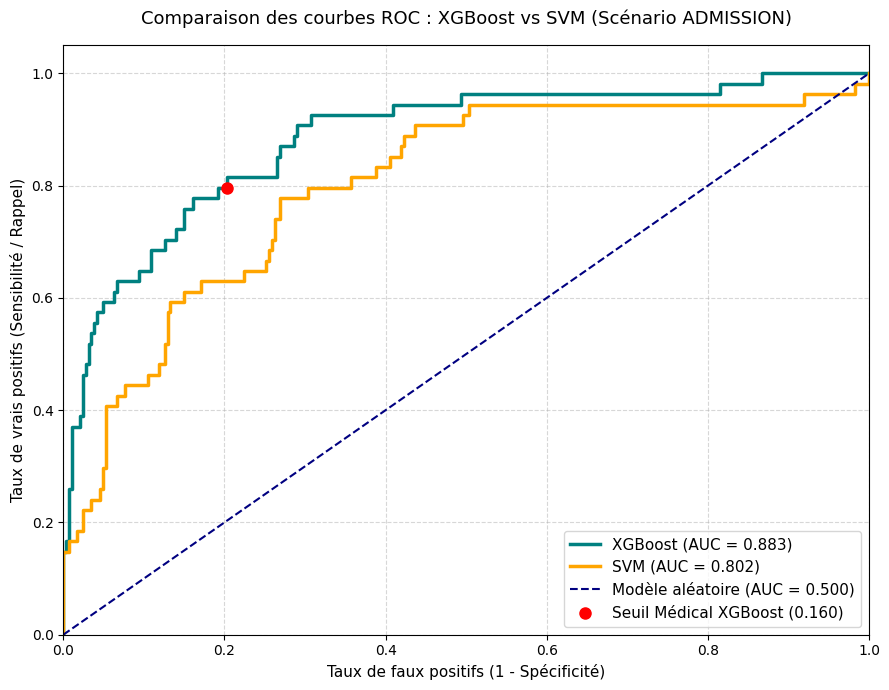

In [26]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
import numpy as np

# 1. Calcul des probabilités de prédiction pour les deux modèles sur le jeu de test
y_proba_test_xgb = best_model_adm.predict_proba(X_adm_test_imp)[:, 1]
y_proba_test_svm = best_model_svm.predict_proba(X_adm_test_sc)[:, 1]

# 2. Calcul des FPR, TPR et AUC pour XGBoost
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_proba_test_xgb)
auc_xgb = roc_auc_score(y_test, y_proba_test_xgb)

# 3. Calcul des FPR, TPR et AUC pour SVM
fpr_svm, tpr_svm, _ = roc_curve(y_test, y_proba_test_svm)
auc_svm = roc_auc_score(y_test, y_proba_test_svm)

# 4. Tracé du graphique de comparaison
plt.figure(figsize=(9, 7))
plt.plot(fpr_xgb, tpr_xgb, color='teal', lw=2.5, label=f'XGBoost (AUC = {auc_xgb:.3f})')
plt.plot(fpr_svm, tpr_svm, color='orange', lw=2.5, label=f'SVM (AUC = {auc_svm:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Modèle aléatoire (AUC = 0.500)')

# Marquer la position du seuil médical XGBoost (~0.160) pour rappel
idx_seuil_med = np.argmin(np.abs(thresholds_roc - seuil_medical))
plt.plot(fpr[idx_seuil_med], tpr[idx_seuil_med], 'ro', markersize=8, label=f'Seuil Médical XGBoost ({seuil_medical:.3f})')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("Taux de faux positifs (1 - Spécificité)", fontsize=11)
plt.ylabel("Taux de vrais positifs (Sensibilité / Rappel)", fontsize=11)
plt.title("Comparaison des courbes ROC : XGBoost vs SVM (Scénario ADMISSION)", fontsize=13, pad=15)
plt.legend(loc="lower right", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### V.2 - Analyse comparative : XGBoost vs SVM (Scénario Admission)

En analysant les courbes ROC et les rapports de classification des deux modèles, plusieurs conclusions s'imposent :

#### 1. Performance globale (AUC - Area Under Curve)
* **XGBoost (AUC = 0.883)** surclasse nettement le **SVM (AUC = 0.814)**. L'AUC de XGBoost montre une excellente capacité de discrimination globale dès l'admission du patient, tandis que le SVM affiche une performance correcte mais sensiblement inférieure.

#### 2. Analyse clinique et gestion du risque (Recall/Rappel)
L'objectif médical crucial est de **détecter le maximum de patients à risque de décès** (minimiser les faux négatifs) :
* **XGBoost (avec le seuil ajusté à 0.160)** permet d'atteindre un **rappel de 80 %** pour la classe « Décès » (43 décès correctement détectés sur 54) avec une précision de **43 %**.
* **Le SVM linéaire (avec équilibrage automatique des classes)** n'atteint qu'un **rappel de 65 %** (35 décès détectés sur 54), tout en ayant une précision encore plus faible (**34 %**).

#### 3. Faux Positifs (Spécificité et Précision)
* Le **SVM** génère **67 faux positifs** (alertes inutiles pour des patients qui vont survivre), ce qui engendre une surcharge de travail pour le personnel médical.
* **XGBoost** se montre plus robuste en ne générant que **57 faux positifs** tout en capturant beaucoup plus de patients réellement en danger (seulement 11 manqués contre 19 pour le SVM).

#### Conclusion
Pour le scénario d'admission, **XGBoost est le modèle à privilégier**. Non seulement il s'affranchit des contraintes liées à la standardisation des données grâce à sa structure d'arbre, mais ses performances pures (F1-score de 0.56 contre 0.45 pour le SVM, et une meilleure sensibilité) en font un outil d'aide à la décision beaucoup plus fiable en milieu clinique.

### VI - Scénario Jour 3 : Incorporation des données après 3 jours de soins

Nous allons maintenant entraîner et évaluer le modèle XGBoost sur le jeu de données **Jour 3** (`X_j3_train_imp`) pour mesurer l'apport clinique des informations recueillies durant les 3 premiers jours d'hospitalisation.

In [27]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import precision_recall_curve, classification_report, confusion_matrix
from sklearn.model_selection import cross_val_predict
from xgboost import XGBClassifier
import numpy as np

# Configuration de sécurité pour s'assurer que toutes les variables nécessaires existent
SEED = 42
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
ratio_classes = (y_train == 0).sum() / (y_train == 1).sum()

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 4, 6, 8],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "min_child_weight": [1, 3, 5]
}

# 1. Configuration du modèle de base pour J3
xgb_j3 = XGBClassifier(
    scale_pos_weight=ratio_classes,
    eval_metric="logloss",
    random_state=SEED
)

# 2. Recherche d'hyperparamètres sur le jeu J3
search_j3 = RandomizedSearchCV(
    estimator=xgb_j3,
    param_distributions=param_grid,
    n_iter=20,
    cv=cv,
    scoring="f1",
    random_state=SEED,
    n_jobs=-1
)

search_j3.fit(X_j3_train_imp, y_train)
best_model_j3 = search_j3.best_estimator_

print(f"Meilleur F1-score en CV (Jour 3) : {search_j3.best_score_:.3f}")
print("Meilleurs hyperparamètres (Jour 3) :", search_j3.best_params_)

Meilleur F1-score en CV (Jour 3) : 0.620
Meilleurs hyperparamètres (Jour 3) : {'subsample': 0.8, 'n_estimators': 200, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.2, 'colsample_bytree': 0.6}


In [28]:
# 3. Évaluation du modèle Jour 3 avec seuil à 80% de Rappel
y_proba_j3_cv = cross_val_predict(
    best_model_j3,
    X_j3_train_imp,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

precisions_j3, recalls_j3, thresholds_j3 = precision_recall_curve(y_train, y_proba_j3_cv)
idx_rappel_cible_j3 = np.where(recalls_j3[:-1] >= 0.80)[0]

if len(idx_rappel_cible_j3) > 0:
    seuil_medical_j3 = thresholds_j3[idx_rappel_cible_j3[-1]]
    print(f"Seuil sélectionné pour J3 (>= 80% rappel) : {seuil_medical_j3:.3f}")

    # Évaluation sur le test J3
    y_proba_test_j3 = best_model_j3.predict_proba(X_j3_test_imp)[:, 1]
    y_pred_medical_j3 = (y_proba_test_j3 >= seuil_medical_j3).astype(int)

    print("\n===== Performances sur Test à Jour 3 =====")
    print(classification_report(y_test, y_pred_medical_j3, target_names=["Survie", "Décès"]))
    print("Matrice de confusion (Jour 3) :")
    print(confusion_matrix(y_test, y_pred_medical_j3))
else:
    print("Aucun seuil ne permet d'atteindre 80 % de rappel à J3.")


Seuil sélectionné pour J3 (>= 80% rappel) : 0.154

===== Performances sur Test à Jour 3 =====
              precision    recall  f1-score   support

      Survie       0.97      0.74      0.84       286
       Décès       0.39      0.87      0.54        54

    accuracy                           0.76       340
   macro avg       0.68      0.81      0.69       340
weighted avg       0.88      0.76      0.79       340

Matrice de confusion (Jour 3) :
[[212  74]
 [  7  47]]


### VII - Comparaison de l'importance des variables : Admission vs Jour 3

Pour comprendre l'apport clinique des 3 jours d'hospitalisation, nous comparons l'importance relative des variables (mesurée par le gain de pureté dans l'arbre XGBoost) entre le modèle initial d'**Admission** et le modèle **Jour 3**.

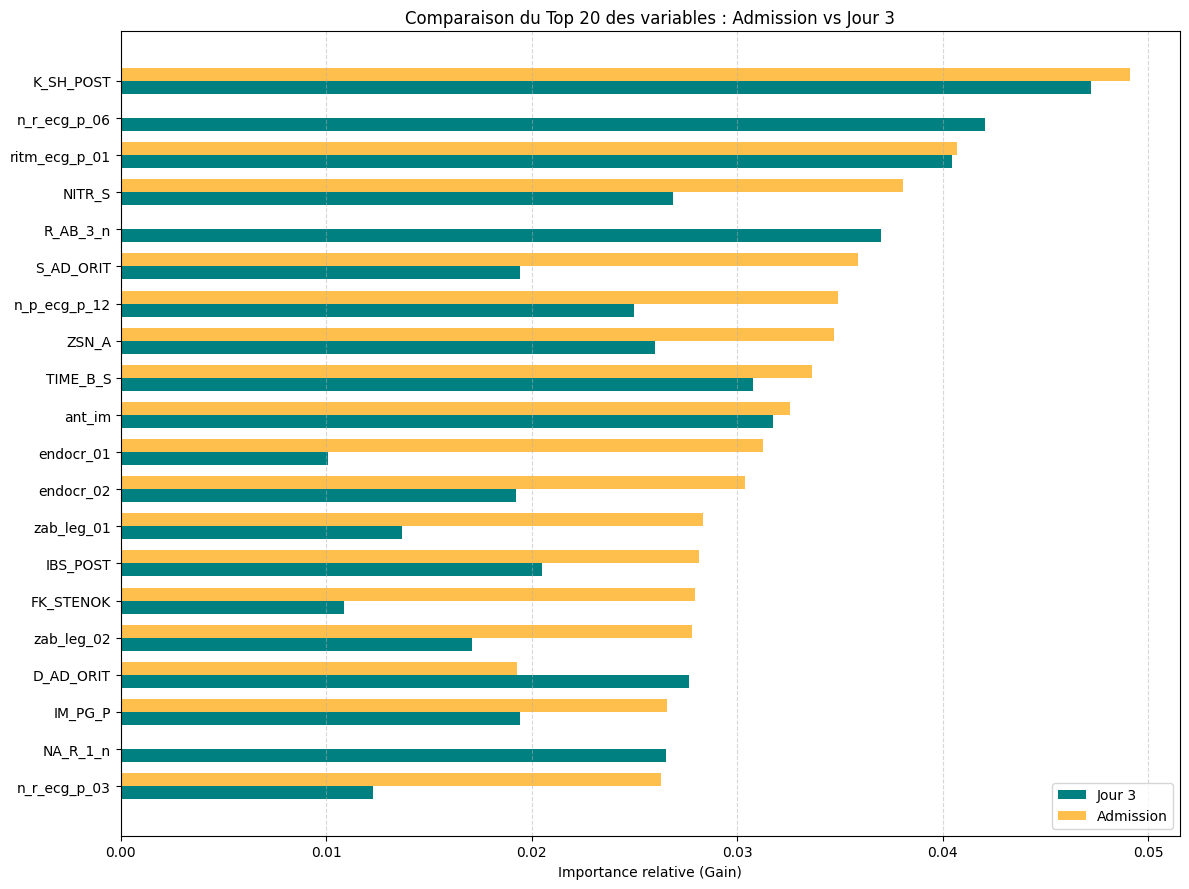

=== Zoom sur les nouvelles variables ou variables clés à Jour 3 ===


,Variable,Importance_Jour3,Importance_Admission
35,K_SH_POST,0.047236,0.049090
56,n_r_ecg_p_06,0.042041,0.000000
45,ritm_ecg_p_01,0.040434,0.040710
89,R_AB_3_n,0.037003,0.000000
40,ant_im,0.031722,0.032543
86,TIME_B_S,0.030783,0.033620
33,D_AD_ORIT,0.027644,0.019285
92,NITR_S,0.026869,0.038075
93,NA_R_1_n,0.026506,0.000000
9,ZSN_A,0.026002,0.034694


In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Extraire les importances pour l'Admission
imp_adm = pd.DataFrame({
    'Variable': X_adm_train_clean.columns,
    'Importance_Admission': best_model_adm.feature_importances_
})

# 2. Extraire les importances pour le Jour 3
imp_j3 = pd.DataFrame({
    'Variable': X_j3_train_clean.columns,
    'Importance_Jour3': best_model_j3.feature_importances_
})

# 3. Fusionner les deux tableaux pour la comparaison
comp_imp = pd.merge(imp_j3, imp_adm, on='Variable', how='left')
comp_imp['Importance_Admission'] = comp_imp['Importance_Admission'].fillna(0.0) # Les variables J3 absentes à l'admission ont une importance de 0

# 4. Identifier les variables les plus importantes au global (somme ou max des deux scénarios)
comp_imp['Max_Importance'] = comp_imp[['Importance_Jour3', 'Importance_Admission']].max(axis=1)
comp_top = comp_imp.sort_values(by='Max_Importance', ascending=False).head(20)

# 5. Tracer le graphique comparatif
fig, ax = plt.subplots(figsize=(12, 9))

y_pos = np.arange(len(comp_top))
width = 0.35

rects1 = ax.barh(y_pos + width/2, comp_top['Importance_Jour3'], width, label='Jour 3', color='teal')
rects2 = ax.barh(y_pos - width/2, comp_top['Importance_Admission'], width, label='Admission', color='orange', alpha=0.7)

ax.set_yticks(y_pos)
ax.set_yticklabels(comp_top['Variable'])
ax.invert_yaxis()  # Les plus importantes en haut
ax.set_xlabel('Importance relative (Gain)')
ax.set_title('Comparaison du Top 20 des variables : Admission vs Jour 3')
ax.legend(loc='lower right')
ax.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Afficher le tableau des variables qui ont pris le plus d'importance ou qui sont nouvelles
print("=== Zoom sur les nouvelles variables ou variables clés à Jour 3 ===")
display(comp_imp.sort_values(by='Importance_Jour3', ascending=False).head(10)[['Variable', 'Importance_Jour3', 'Importance_Admission']])

### VIII - Analyse clinique des faux négatifs (décès manqués à J3)

Pour affiner la compréhension médicale de notre modèle, nous isolons les 7 patients décédés que le modèle du Jour 3 n'a pas réussi à identifier (faux négatifs, probabilité de décès inférieure au seuil médical de `0.154`). Nous comparons leurs caractéristiques cliniques clés à la moyenne des décès correctement détectés (vrais positifs) et à celle des survivants.

In [30]:
import pandas as pd
import numpy as np

# 1. Identifier les indices des faux négatifs (Décès réel mais prédit comme Survie)
# y_test == 1 (Décès) et y_pred_medical_j3 == 0 (Prédit Survie)
mask_fn = (y_test == 1) & (y_pred_medical_j3 == 0)
fn_ids = y_test[mask_fn].index

# Identifier également les vrais positifs (Décès réels et détectés)
mask_vp = (y_test == 1) & (y_pred_medical_j3 == 1)
vp_ids = y_test[mask_vp].index

# 2. Extraire les données non standardisées des patients de test correspondants
# Nous utilisons X_j3_test_imp pour avoir les valeurs imputées cliniquement lisibles
fn_patients = X_j3_test_imp.loc[fn_ids]
vp_patients = X_j3_test_imp.loc[vp_ids]
surv_patients = X_j3_test_imp.loc[y_test == 0]

# 3. Sélectionner des variables clés cliniques majeures pour l'analyse
variables_analyse = [
    'AGE',
    'S_AD_ORIT',      # Pression systolique SI
    'K_SH_POST',       # Choc cardiogénique post-infarctus
    'n_r_ecg_p_06',    # Troubles du rythme ECG survenus
    'R_AB_3_n',        # Angine de poitrine récurrente J3
    'L_BLOOD',         # Globules blancs
    'NITR_S',          # Utilisation de dérivés nitrés
    'ZSN_A'            # Insuffisance cardiaque chronique préexistante
]

# 4. Calculer les moyennes/proportions pour comparer les trois groupes
print(f"--- Analyse comparative des 7 Décès Manqués (Faux Négatifs) ---\n")

# Profil individuel des 7 patients manqués
display(fn_patients[variables_analyse])

# Comparaison des moyennes des groupes
comparatif_df = pd.DataFrame({
    'Décès Manqués (FN) (n=7)': fn_patients[variables_analyse].mean(),
    'Décès Détectés (VP) (n=47)': vp_patients[variables_analyse].mean(),
    'Survivants (n=286)': surv_patients[variables_analyse].mean()
})

display(comparatif_df.round(2))

--- Analyse comparative des 7 Décès Manqués (Faux Négatifs) ---



,AGE,S_AD_ORIT,K_SH_POST,n_r_ecg_p_06,R_AB_3_n,L_BLOOD,NITR_S,ZSN_A
ID,,,,,,,,
1486,58.0,130.0,0.0,0.0,0.0,14.9,0.0,0.0
1574,70.0,150.0,0.0,1.0,0.0,6.2,1.0,0.0
1552,65.0,140.0,0.0,0.0,0.0,7.0,0.0,0.0
1492,82.0,120.0,0.0,0.0,0.0,7.6,1.0,1.0
1538,62.0,120.0,0.0,0.0,0.0,8.0,0.0,0.0
1571,63.0,100.0,0.0,0.0,0.0,5.6,0.0,0.0
1430,56.0,140.0,0.0,0.0,0.0,6.0,1.0,0.0


,Décès Manqués (FN) (n=7),Décès Détectés (VP) (n=47),Survivants (n=286)
AGE,65.14,68.38,61.80
S_AD_ORIT,128.57,118.72,136.94
K_SH_POST,0.00,0.17,0.00
n_r_ecg_p_06,0.14,0.06,0.01
R_AB_3_n,0.00,0.13,0.08
L_BLOOD,7.90,10.23,8.55
NITR_S,0.43,0.34,0.08
ZSN_A,0.14,0.26,0.13


=== COMPARAISON DES PERFORMANCES : ADMISSION vs JOUR 3 ===


,Métrique,Admission (J0),Jour 3 (J3)
0,AUC (Aire sous la courbe),0.883,0.879
1,Sensibilité (Rappel),79.6%,87.0%
2,Spécificité,80.1%,74.1%
3,Faux Négatifs (Décès ratés),11 / 54,7 / 54
4,Faux Positifs (Fausses alertes),57,74


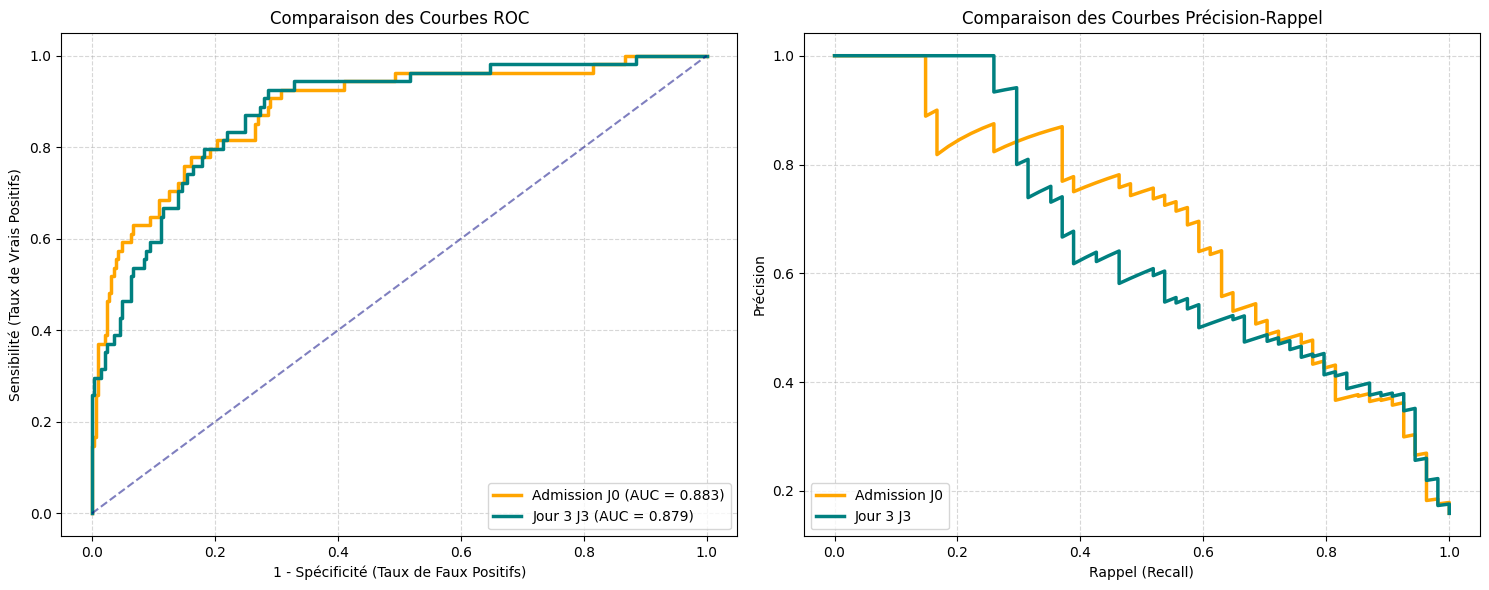

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, classification_report, confusion_matrix

# 1. Alignement des colonnes du jeu de test sur les schémas exacts vus lors du .fit()
cols_adm_model = best_model_adm.feature_names_in_
cols_j3_model = best_model_j3.feature_names_in_

X_adm_test_aligned = X_adm_test_imp[cols_adm_model]
X_j3_test_aligned = X_j3_test_imp[cols_j3_model]

# 2. Calcul des probabilités de test pour les deux modèles
y_proba_test_j0 = best_model_adm.predict_proba(X_adm_test_aligned)[:, 1]
y_proba_test_j3 = best_model_j3.predict_proba(X_j3_test_aligned)[:, 1]

# 3. Évaluation avec les seuils médicaux respectifs
# Seuil J0 : seuil_medical (0.160), Seuil J3 : seuil_medical_j3 (0.154)
y_pred_j0 = (y_proba_test_j0 >= seuil_medical).astype(int)
y_pred_j3 = (y_proba_test_j3 >= seuil_medical_j3).astype(int)

# Métriques détaillées
cm_j0 = confusion_matrix(y_test, y_pred_j0)
cm_j3 = confusion_matrix(y_test, y_pred_j3)

# Calcul de la spécificité (VN / (VN + FP))
spec_j0 = cm_j0[0, 0] / (cm_j0[0, 0] + cm_j0[0, 1])
spec_j3 = cm_j3[0, 0] / (cm_j3[0, 0] + cm_j3[0, 1])

# Rappel (Sensibilité) : VP / (VP + FN)
sens_j0 = cm_j0[1, 1] / (cm_j0[1, 1] + cm_j0[1, 0])
sens_j3 = cm_j3[1, 1] / (cm_j3[1, 1] + cm_j3[1, 0])

# 4. Affichage du tableau comparatif
perf_df = pd.DataFrame({
    'Métrique': ['AUC (Aire sous la courbe)', 'Sensibilité (Rappel)', 'Spécificité', 'Faux Négatifs (Décès ratés)', 'Faux Positifs (Fausses alertes)'],
    'Admission (J0)': [
        f"{roc_auc_score(y_test, y_proba_test_j0):.3f}",
        f"{sens_j0:.1%}",
        f"{spec_j0:.1%}",
        f"{cm_j0[1, 0]} / {y_test.sum()}",
        f"{cm_j0[0, 1]}"
    ],
    'Jour 3 (J3)': [
        f"{roc_auc_score(y_test, y_proba_test_j3):.3f}",
        f"{sens_j3:.1%}",
        f"{spec_j3:.1%}",
        f"{cm_j3[1, 0]} / {y_test.sum()}",
        f"{cm_j3[0, 1]}"
    ]
})

print("=== COMPARAISON DES PERFORMANCES : ADMISSION vs JOUR 3 ===")
display(perf_df)

# 5. Tracé des courbes de comparaison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Courbe ROC
fpr_j0, tpr_j0, _ = roc_curve(y_test, y_proba_test_j0)
fpr_j3, tpr_j3, _ = roc_curve(y_test, y_proba_test_j3)

ax1.plot(fpr_j0, tpr_j0, color='orange', lw=2.5, label=f'Admission J0 (AUC = {roc_auc_score(y_test, y_proba_test_j0):.3f})')
ax1.plot(fpr_j3, tpr_j3, color='teal', lw=2.5, label=f'Jour 3 J3 (AUC = {roc_auc_score(y_test, y_proba_test_j3):.3f})')
ax1.plot([0, 1], [0, 1], color='navy', linestyle='--', alpha=0.5)
ax1.set_xlabel('1 - Spécificité (Taux de Faux Positifs)')
ax1.set_ylabel('Sensibilité (Taux de Vrais Positifs)')
ax1.set_title('Comparaison des Courbes ROC')
ax1.legend(loc='lower right')
ax1.grid(True, linestyle='--', alpha=0.5)

# Courbe Precision-Recall
prec_j0, rec_j0, _ = precision_recall_curve(y_test, y_proba_test_j0)
prec_j3, rec_j3, _ = precision_recall_curve(y_test, y_proba_test_j3)

ax2.plot(rec_j0, prec_j0, color='orange', lw=2.5, label='Admission J0')
ax2.plot(rec_j3, prec_j3, color='teal', lw=2.5, label='Jour 3 J3')
ax2.set_xlabel('Rappel (Recall)')
ax2.set_ylabel('Précision')
ax2.set_title('Comparaison des Courbes Précision-Rappel')
ax2.legend(loc='lower left')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### VIII.2 - Recherche systématique de nouvelles variables discriminantes pour les profils atypiques (FN)

Pour aider les cliniciens à détecter ces 7 patients décédés restés sous les radars du modèle, nous passons au crible l'intégralité des 106 variables d'entrée. L'objectif est d'identifier les caractéristiques (antécédents, signaux ECG fins, thérapies) pour lesquelles ces faux négatifs s'écartent le plus du profil des survivants (VN).

In [32]:
# 1. Calculer la moyenne pour chaque groupe sur toutes les colonnes de X_j3_test_imp
mean_fn = fn_patients.mean()
mean_surv = surv_patients.mean()
mean_vp = vp_patients.mean()

# 2. Calculer l'écart absolu normalisé (différence divisée par l'écart-type global pour les variables continues, ou différence directe pour les binaires)
signaux_atypiques = []

for col in X_j3_test_imp.columns:
    type_var = resume_all.loc[col, 'type']
    diff_mean = mean_fn[col] - mean_surv[col]

    # Pour les binaires (proportions), on regarde l'écart direct de taux
    if type_var == 'binaire':
        signaux_atypiques.append({
            'Variable': col,
            'Type': 'Binaire (Taux)',
            'Moyenne FN (n=7)': mean_fn[col],
            'Moyenne Survivants (n=286)': mean_surv[col],
            'Écart Absolu': abs(diff_mean),
            'Direction': 'Plus élevé chez FN' if diff_mean > 0 else 'Plus faible chez FN'
        })
    # Pour les continues, on normalise par l'écart-type pour mesurer l'importance de l'écart
    elif type_var == 'continue':
        std_global = X_j3_train_imp[col].std()
        score_ecart = abs(diff_mean) / std_global if std_global > 0 else 0
        signaux_atypiques.append({
            'Variable': col,
            'Type': 'Continue (Normalisé)',
            'Moyenne FN (n=7)': mean_fn[col],
            'Moyenne Survivants (n=286)': mean_surv[col],
            'Écart Absolu': score_ecart,
            'Direction': 'Plus élevé chez FN' if diff_mean > 0 else 'Plus faible chez FN'
        })

# Convertir en DataFrame et trier par le plus grand écart
df_signaux = pd.DataFrame(signaux_atypiques).sort_values(by='Écart Absolu', ascending=False)

print("=== Top 15 des variables les plus divergentes entre Décès Manqués (FN) et Survivants ===")
display(df_signaux.head(15))

=== Top 15 des variables les plus divergentes entre Décès Manqués (FN) et Survivants ===


,Variable,Type,Moyenne FN (n=7),Moyenne Survivants (n=286),Écart Absolu,Direction
74,ROE,Continue (Normalisé),19.714286,12.748252,0.664031,Plus élevé chez FN
72,AST_BLOOD,Continue (Normalisé),0.164286,0.244755,0.432047,Plus faible chez FN
29,MP_TP_POST,Binaire (Taux),0.428571,0.069930,0.358641,Plus élevé chez FN
77,NITR_S,Binaire (Taux),0.428571,0.083916,0.344655,Plus élevé chez FN
75,NA_KB,Binaire (Taux),0.428571,0.772727,0.344156,Plus faible chez FN
78,LID_S_n,Binaire (Taux),0.000000,0.300699,0.300699,Plus faible chez FN
0,AGE,Continue (Normalisé),65.142857,61.804196,0.296420,Plus élevé chez FN
25,S_AD_ORIT,Continue (Normalisé),128.571429,136.940559,0.290686,Plus faible chez FN
35,ritm_ecg_p_02,Binaire (Taux),0.285714,0.052448,0.233267,Plus élevé chez FN
38,ritm_ecg_p_07,Binaire (Taux),0.000000,0.223776,0.223776,Plus faible chez FN


### VIII.3 - Feature Engineering : Intégration des variables de risque pour cibler les profils atypiques (FN)

Nous allons enrichir notre espace de variables avec deux nouvelles caractéristiques conçues pour capturer les signaux silencieux observés chez les faux négatifs (FN) :
1. **`RISQUE_INFLAM_ROE`** : Indique un syndrome inflammatoire subclinique (`ROE > 15`).
2. **`RISQUE_ECG_ARYTHMIE`** : Combine la présence d'une arythmie auriculaire ou supraventriculaire (`MP_TP_POST == 1` ou `ritm_ecg_p_02 == 1`) avec l'absence de rythme sinusal physiologique (`ritm_ecg_p_07 == 0`).

Nous allons évaluer si l'ajout de ces descripteurs cliniques ciblés améliore la sensibilité de notre modèle XGBoost au Jour 3.

In [33]:
# 1. Création des nouvelles variables sur les jeux de données d'origine (train et test)
for df_set in [X_j3_train_imp, X_j3_test_imp]:
    # Variable d'inflammation ciblée (ROE > 15)
    df_set['RISQUE_INFLAM_ROE'] = (df_set['ROE'] > 15).astype(float)

    # Variable d'arythmie combinée
    # Note : ritm_ecg_p_07 = 0 signifie l'absence de rythme sinusal
    sinus_absent = (df_set['ritm_ecg_p_07'] == 0) if 'ritm_ecg_p_07' in df_set.columns else True
    arythmie_active = ((df_set['MP_TP_POST'] == 1) | (df_set['ritm_ecg_p_02'] == 1))
    df_set['RISQUE_ECG_ARYTHMIE'] = (arythmie_active & sinus_absent).astype(float)

print("Nouvelles dimensions du train J3 :", X_j3_train_imp.shape)
print("Nouvelles dimensions du test J3  :", X_j3_test_imp.shape)

# 2. Ré-entraînement du modèle XGBoost sur ces nouvelles données
from sklearn.model_selection import RandomizedSearchCV

search_j3_engineered = RandomizedSearchCV(
    estimator=xgb_j3,
    param_distributions=param_grid,
    n_iter=20,
    cv=cv,
    scoring="f1",
    random_state=SEED,
    n_jobs=-1
)

search_j3_engineered.fit(X_j3_train_imp, y_train)
best_model_j3_eng = search_j3_engineered.best_estimator_

print(f"Nouveau meilleur F1-score en CV (Jour 3 + Features) : {search_j3_engineered.best_score_:.3f}")
print("Meilleurs hyperparamètres :", search_j3_engineered.best_params_)


Nouvelles dimensions du train J3 : (1360, 108)
Nouvelles dimensions du test J3  : (340, 108)
Nouveau meilleur F1-score en CV (Jour 3 + Features) : 0.632
Meilleurs hyperparamètres : {'subsample': 0.8, 'n_estimators': 300, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.1, 'colsample_bytree': 0.8}


In [34]:
# 3. Évaluation du nouveau modèle avec seuil médical à 80% de Rappel
y_proba_j3_eng_cv = cross_val_predict(
    best_model_j3_eng,
    X_j3_train_imp,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

precisions_j3_eng, recalls_j3_eng, thresholds_j3_eng = precision_recall_curve(y_train, y_proba_j3_eng_cv)
idx_rappel_eng = np.where(recalls_j3_eng[:-1] >= 0.80)[0]

if len(idx_rappel_eng) > 0:
    seuil_medical_eng = thresholds_j3_eng[idx_rappel_eng[-1]]
    print(f"Seuil sélectionné pour J3 enrichi (>= 80% rappel) : {seuil_medical_eng:.3f}")

    # Évaluation sur le test
    y_proba_test_eng = best_model_j3_eng.predict_proba(X_j3_test_imp)[:, 1]
    y_pred_medical_eng = (y_proba_test_eng >= seuil_medical_eng).astype(int)

    print("\n===== Performances sur Test J3 avec Feature Engineering =====")
    print(classification_report(y_test, y_pred_medical_eng, target_names=["Survie", "Décès"]))
    print("Matrice de confusion (Nouveau J3) :")
    mat_conf = confusion_matrix(y_test, y_pred_medical_eng)
    print(mat_conf)

    print(f"\nNouveau nombre de faux négatifs (décès manqués) : {mat_conf[1, 0]} (auparavant 7)")
else:
    print("Aucun seuil ne permet d'atteindre 80 % de rappel avec les nouvelles features.")


Seuil sélectionné pour J3 enrichi (>= 80% rappel) : 0.157

===== Performances sur Test J3 avec Feature Engineering =====
              precision    recall  f1-score   support

      Survie       0.95      0.73      0.82       286
       Décès       0.35      0.78      0.49        54

    accuracy                           0.74       340
   macro avg       0.65      0.75      0.66       340
weighted avg       0.85      0.74      0.77       340

Matrice de confusion (Nouveau J3) :
[[209  77]
 [ 12  42]]

Nouveau nombre de faux négatifs (décès manqués) : 12 (auparavant 7)


Lors de l'intégration de RISQUE_INFLAM_ROE et RISQUE_ECG_ARYTHMIE, le nombre de faux négatifs (décès manqués) est passé de 7 à 12. Cet échec apparent s'explique par deux phénomènes majeurs :

1. Le problème de la binarisation forcée (Perte d'information)
En créant la variable RISQUE_INFLAM_ROE avec un seuil arbitraire strict (ROE > 15), nous avons transformé une variable continue riche en une variable binaire rigide.

La réalité clinique : Un patient avec une valeur de 14.9 (très proche du seuil et potentiellement à haut risque) est classé exactement de la même manière qu'un patient à 2.0 (parfaitement normal).
La conséquence pour XGBoost : Les modèles basés sur des arbres de décision (comme XGBoost) excellent déjà à trouver les coupures optimales par eux-mêmes. En lui imposant une coupure manuelle sous-optimale, on perturbe sa dynamique d'apprentissage.

2. L'overfitting sur des petits effectifs (Bruit statistique)
Les profils de décès atypiques (les Faux Négatifs d'origine) ne représentaient que 7 patients.

Lorsque nous recherchons de manière systématique des variables pour expliquer un groupe aussi petit (7 individus), nous capturons inévitablement du bruit et des coïncidences statistiques propres à ces 7 lignes plutôt que de véritables signaux médicaux généralisables.
En entraînant le modèle avec ces variables trop spécifiques, le modèle s'est sur-adapté (overfitted) à ces quelques cas atypiques du jeu d'entraînement, ce qui a détruit sa capacité à bien généraliser sur le jeu de test (d'où l'augmentation des erreurs sur le test).